# ChIP-seq: where does the transcription factor CEBPA bind in the human liver?

**Case study: binding sites of the liver transcription factor CEBPA**

Ballester B, Medina-Rivera A, Schmidt D, et al. *Multi-species, multi-transcription factor binding highlights conserved control of tissue-specific biological pathways.* eLife (2014) 3:e02626. https://elifesciences.org/articles/02626

**Background**

Cell identity is controlled by transcription factors (TFs): proteins that bind short DNA sequences (*motifs*) in promoters and enhancers and switch genes on or off. In the liver, a small set of TFs (CEBPA, HNF4A, FOXA1 and ONECUT1/HNF6) controls the expression of the genes that make a hepatocyte a hepatocyte: plasma proteins such as albumin, apolipoproteins, coagulation factors and drug metabolising enzymes (cytochrome P450s).

**CEBPA** (CCAAT/enhancer binding protein alpha) is a *basic leucine zipper* (bZIP) TF. It binds DNA as a dimer and recognises the palindromic motif `TTGCGCAA`. Besides the liver, CEBPA is also important in fat cells (adipocytes) and in the myeloid lineage of the blood (neutrophils, monocytes, macrophages).

The authors mapped the binding sites of these four TFs in the livers of five species (human, macaque, dog, rat and mouse) using **ChIP-seq** (chromatin immunoprecipitation followed by sequencing). We will analyse the human CEBPA ChIP-seq experiment together with its control (Input).

**Research questions:**

1. Where in the genome does CEBPA bind? Close to promoters or further away, in enhancers?
2. Which DNA motif is enriched in the CEBPA bound regions? Is it the CEBP motif?
3. Which genes and biological processes are close to CEBPA binding sites? Are these liver functions?
4. Are the CEBPA bound regions *active* enhancers (marked by the histone modification H3K27ac) in the liver? And are they also active in another tissue (spleen)?

In this notebook we go from raw sequencing reads to peaks, and use these peaks to answer the questions above.

## Introduction: ChIP-seq

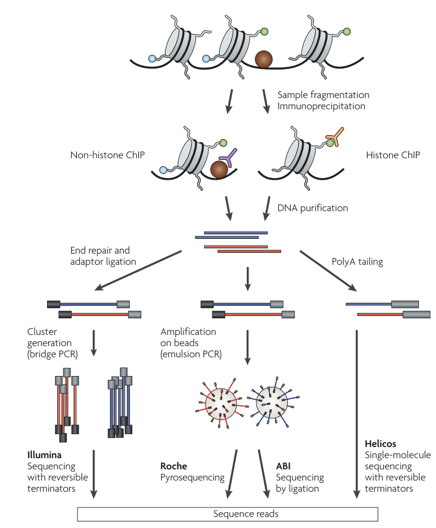

ChIP-seq is used to map the location of proteins on DNA/chromatin, such as transcription factors (TF ChIP-seq) or modified histones (histone ChIP-seq). The chromatin is cross-linked (proteins are fixed to the DNA using formaldehyde) and sheared into small fragments (~ 200 - 500 bp). An antibody against the protein of interest is used to pull down (immunoprecipitate) the fragments bound by this protein. After reversing the cross-links, the DNA fragments are sequenced. Regions bound by the protein will be covered by many more reads than the rest of the genome: they show up as a **peak**.

For more info, see the [review paper](https://www.nature.com/articles/nrg2641) by Park, Nature Reviews Genetics, 2009.

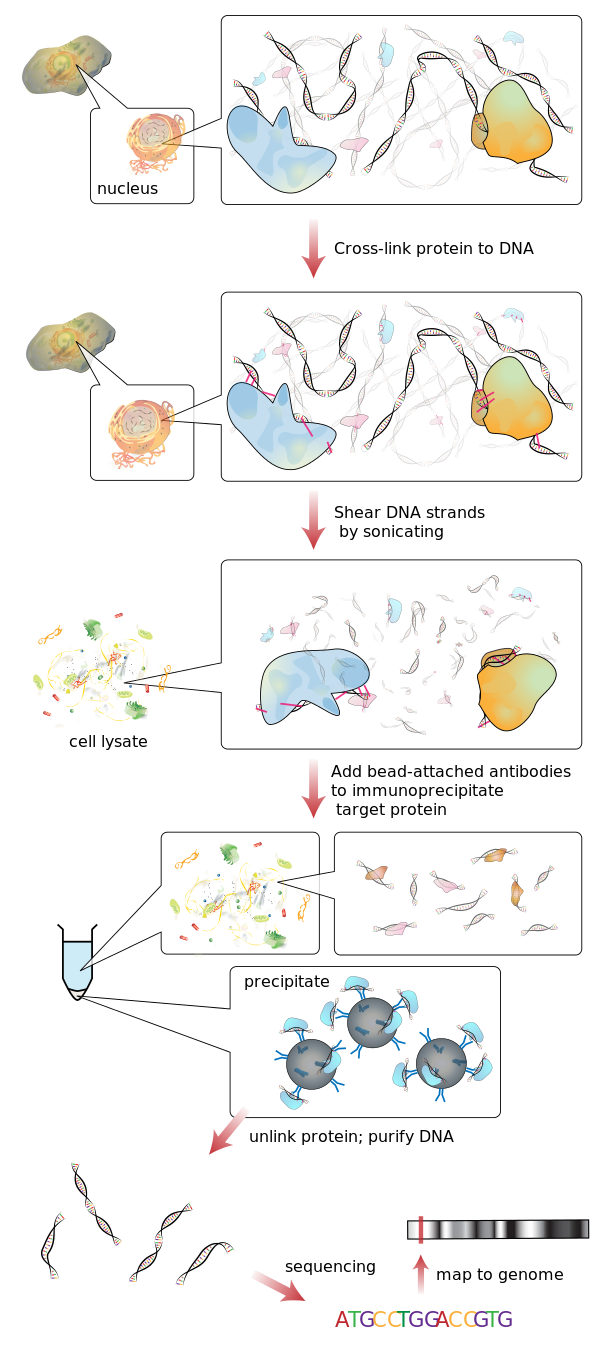

Here's another illustration - from Wikipedia, see https://en.wikipedia.org/wiki/ChIP-sequencing

Not all fragments in a ChIP sample come from bound regions: there is always background, and some regions of the genome are over-represented in any sequencing library (e.g. open chromatin is sheared more easily, repeats, copy number gains). For this reason a **control** sample is sequenced as well. The most common control is the **Input**: chromatin that went through the same procedure, but without the immunoprecipitation step. We only call a peak if the ChIP sample is enriched compared to the Input.

Additional resources:

- ENCODE Data Standards and Processing Pipeline Information for [Histone](https://www.encodeproject.org/chip-seq/histone/) and [Transcription Factors](https://www.encodeproject.org/chip-seq/transcription_factor/)
- [ChIP-seq guidelines and practices of the ENCODE and modENCODE consortia](https://genome.cshlp.org/content/22/9/1813): an older paper but a good outline of general best practices.
- [Hands-on introduction to ChIP-seq analysis](https://www.bio.ens.psl.eu/~mthomas/other/chip-seq-training/)
- [Data Processing for Next Generation Sequencing](https://ss-lab-cancerunit.github.io/NGSdataProcessing/)

**Note**:

This notebook uses a *bash* kernel. All software is installed in a single mamba environment, with the exact versions that were used to make this notebook. This environment also contains `bash_kernel`, which allows us to run bash commands in a Jupyter notebook.

    mamba create -n chipseq -c conda-forge -c bioconda --strict-channel-priority \
        fastqc=0.12.1 multiqc=1.35 bowtie2=2.5.4 samtools=1.22.1 bedtools=2.31.1 \
        deeptools=3.5.6 macs3=3.1.0 homer=5.1 bash_kernel curl bc

- FastQC and MultiQC: quality control of the reads
- Bowtie2: alignment of the reads to the genome
- SAMtools and bedtools: working with BAM and BED files
- deepTools: coverage tracks (bigWig), fingerprint plots and heatmaps
- MACS3: peak calling and differential analysis
- HOMER: peak annotation, motif analysis and gene ontology

HOMER needs a copy of the genome (and its gene annotation) for motif and annotation analysis. This is installed once with (~ 15 minutes, ~ 3 GB):

    mamba activate chipseq
    perl ${CONDA_PREFIX}/share/homer/configureHomer.pl -install hg38

To use the `chipseq` environment in Jupyter we have to register it as a *kernel*. Run the following commands in a terminal (not in this notebook):

```
mamba activate chipseq
KERNEL_DIR=$(jupyter --data-dir)/kernels/bash-chipseq
mkdir -p ${KERNEL_DIR}
cat > ${KERNEL_DIR}/kernel.json << EOF
{
  "argv": ["${CONDA_PREFIX}/bin/python", "-m", "bash_kernel", "-f", "{connection_file}"],
  "display_name": "Bash (ChIP-seq)",
  "language": "bash",
  "env": {"PATH": "${CONDA_PREFIX}/bin:/usr/local/bin:/usr/bin:/bin", "CHIPSEQ_ENV": "${CONDA_PREFIX}", "PS1": "$"}
}
EOF
jupyter kernelspec list   # the kernel bash-chipseq should be listed
```

The file `kernel.json` tells Jupyter how to start the kernel: using the python of the `chipseq` environment (`${CONDA_PREFIX}` is the location of the active environment). We also put the `bin` folder of the environment at the start of the `PATH`, so the tools (bowtie2, samtools, ...) of the environment are found, even when Jupyter itself is started from another environment, and we store the location of the environment in the variable `CHIPSEQ_ENV` (we will use it in Step 0).

Next, (re)start Jupyter and select the kernel "Bash (ChIP-seq)" (Kernel > Change Kernel).

Some steps (motif analysis, peak calling and differential analysis of the H3K27ac data) take some time (5 - 15 minutes). For these steps the expected run time is mentioned.

## Step 0: set up working directory and software

The bash kernel reads your `~/.bashrc` when it starts. If this file adds other software to the `PATH` (for example `conda init` adds the base conda environment), a program with the same name in another environment could be used instead of the one in the `chipseq` environment. To be sure, we put the `bin` folder of the `chipseq` environment (stored in `CHIPSEQ_ENV` by the kernel, see the note above) at the start of the `PATH` again.

Next we check that all tools are found. `which` prints the location of a program: all tools should be in the `bin` folder of the `chipseq` environment (to keep the output short, we print `${CHIPSEQ_ENV}` instead of the full location of the environment).

In [1]:
export PATH=${CHIPSEQ_ENV}/bin:${PATH}
for tool in fastqc multiqc bowtie2 samtools bedtools bamCoverage macs3 findMotifsGenome.pl
do
    echo -e "${tool}\t$(which ${tool} | sed "s|${CHIPSEQ_ENV}|\${CHIPSEQ_ENV}|")"
done

fastqc	${CHIPSEQ_ENV}/bin/fastqc


multiqc	${CHIPSEQ_ENV}/bin/multiqc


bowtie2	${CHIPSEQ_ENV}/bin/bowtie2


samtools	${CHIPSEQ_ENV}/bin/samtools


bedtools	${CHIPSEQ_ENV}/bin/bedtools


bamCoverage	${CHIPSEQ_ENV}/bin/bamCoverage


macs3	${CHIPSEQ_ENV}/bin/macs3


findMotifsGenome.pl	${CHIPSEQ_ENV}/bin/findMotifsGenome.pl


All data will be stored in the folder `data`, next to this notebook. Running the full analysis requires ~ 30 GB of disk space.

In [2]:
mkdir -p data
cd data

We will store the location of the reference genome (the Bowtie2 index, see Step 3) in a variable, so we only have to change it in one place. We use the human reference genome hg38 (GRCh38) of [Illumina iGenomes](https://support.illumina.com/sequencing/sequencing_software/igenome.html), which is already available on the cluster.

In [3]:
GENOME_DIR=/lustre1/project/res_00001/genomes/homo_sapiens/hg38_iGenomes
BOWTIE2_INDEX=${GENOME_DIR}/indexes/Bowtie2/genome
ls ${GENOME_DIR}/indexes/Bowtie2/

genome.1.bt2  genome.3.bt2  genome.fa         genome.rev.2.bt2


genome.2.bt2  genome.4.bt2  genome.rev.1.bt2


## Step 1: get reads

The data is deposited in the European Nucleotide Archive (ENA) under project accession PRJEB1571 (and in ArrayExpress under E-MTAB-1509):

https://www.ebi.ac.uk/ena/browser/view/PRJEB1571

If you follow the link you will find each sequencing run as a separate entry (ERR number). The project contains ChIP-seq data of CEBPA, HNF4A, FOXA1 and HNF6 in the liver of five species (*Homo sapiens*, *Macaca mulatta*, *Canis lupus familiaris*, *Rattus norvegicus* and *Mus musculus*). We only need two runs:

| ENA run | Species | Sample | Our sample name |
|---|---|---|---|
| ERR235723 | *Homo sapiens* | ChIP with an antibody against CEBPA | CEBPA |
| ERR235771 | *Homo sapiens* | Input (control, no antibody) | Input |

In the ENA browser you can also see that these libraries are **single-end**, sequenced on an Illumina Genome Analyzer II with reads of 44 bp. For single-end data there is only one fastq file per sample: each DNA fragment is sequenced from one end only.

ENA provides direct (ftp/https) links to the fastq files, so we can download them using `curl`. Let's first test this on a few reads: we stream the file, decompress it (`gzip -dc`) and only show the first 8 lines (`head -n 8`).

In [4]:
# -f: fail on server errors, -s: silent, -S: show errors, -L: follow redirects
curl -fsSL https://ftp.sra.ebi.ac.uk/vol1/fastq/ERR235/ERR235723/ERR235723.fastq.gz 2> /dev/null \
    | gzip -dc \
    | head -n 8

@ERR235723.1 HWI-EAS350_127:5:1:0:92/1


NCCATGTTAATAAATTTGTATTCTTCTTCTCCTATTCACCGTCC


+


%,7;<:<<<9<<<<::969959<<<<<9;;;;;;<:<#######


@ERR235723.2 HWI-EAS350_127:5:1:0:476/1


NACACATCATGCTCTTTCTCTGCTTTGGTGCTGTGCCGATGCCT


+


%08662664688899888996668885/3368987885/36866


Let's download both files (~ 300 MB and ~ 200 MB, this takes a few minutes). We directly rename the files to our sample names.

In [5]:
mkdir -p fastq_files
# -o: name of the output file, --retry 3: try again (up to 3 times) if the download fails
curl -fsSL --retry 3 -o fastq_files/CEBPA.fastq.gz https://ftp.sra.ebi.ac.uk/vol1/fastq/ERR235/ERR235723/ERR235723.fastq.gz
curl -fsSL --retry 3 -o fastq_files/Input.fastq.gz https://ftp.sra.ebi.ac.uk/vol1/fastq/ERR235/ERR235771/ERR235771.fastq.gz
# -l: long listing format, -h: human readable file sizes, -g -G: don't show the owner and group of the files
ls -lhgG fastq_files

total 492M


-rw-rw----+ 1 307M Oct 28 19:32 CEBPA.fastq.gz


-rw-rw----+ 1 192M Oct 28 19:34 Input.fastq.gz


In [4]:
zcat fastq_files/CEBPA.fastq.gz | head -n 4

@ERR235723.1 HWI-EAS350_127:5:1:0:92/1


NCCATGTTAATAAATTTGTATTCTTCTTCTCCTATTCACCGTCC


+


%,7;<:<<<9<<<<::969959<<<<<9;;;;;;<:<#######


For each read there are 4 lines in a fastq file:

1. sequence identifier (starts with `@`): the read number in ENA (ERR235723.1), followed by the original name given by the sequencer (instrument name, run, lane, tile and x/y coordinates of the cluster). `/1` means this is read 1 (the only read for single-end data).
2. raw sequence (44 bases)
3. description (starts with `+`)
4. quality of each base, encoded as an ASCII character: the quality score Q is the ASCII value minus 33, and $Q = -10 \log_{10}P$, with P the probability that the base was called incorrectly. So a Q of 30 (the character `?`) means a 1 in 1000 chance that the base is wrong.

Quality characters, from low to high quality:
```
!"#$%&'()*+,-./0123456789:;<=>?@ABCDEFGHIJKLMNOPQRSTUVWXYZ[\]^_`abcdefghijklmnopqrstuvwxyz{|}~
```

This first read starts with an `N` (base could not be called) with a very low quality (`%`, Q = 4) and the last bases have the lowest possible quality (`#`, Q = 2). The first reads of a run come from the edge of the flow cell and are often of lower quality.

Let's count the number of reads. Remember: number of reads = number of lines / 4.

In [7]:
for sample in CEBPA Input
do
    echo -e "${sample}\t$(zcat fastq_files/${sample}.fastq.gz | awk 'END {print NR/4}') reads"
done

CEBPA	7209060 reads


Input	4566628 reads


This is consistent with the number of reads (*read count*) on the ENA page of these runs.

**Question**: The CEBPA sample has ~ 7.2 million reads. The human genome is ~ 3.1 billion bases long. If the reads were spread uniformly over the genome, what would be the average coverage (how many reads overlap a given base)? Do you think that is enough to detect binding sites?

## Step 2: quality control using FastQC

After receiving sequencing data your first step should be to check the data quality. [FastQC](http://www.bioinformatics.babraham.ac.uk/projects/fastqc/) produces a quality report for a fastq file.

    fastqc fastqfile --outdir outputdir

Useful links:

* [FastQC report for a good Illumina dataset](http://www.bioinformatics.babraham.ac.uk/projects/fastqc/good_sequence_short_fastqc.html)
* [FastQC report for a bad Illumina dataset](http://www.bioinformatics.babraham.ac.uk/projects/fastqc/bad_sequence_fastqc.html)
* [Online documentation for each FastQC report](http://www.bioinformatics.babraham.ac.uk/projects/fastqc/Help/3%20Analysis%20Modules/)

The FastQC reports most useful for ChIP-seq are:

* The **Per base sequence quality** report, which can help you decide if trimming is needed before alignment.
* The **Sequence Duplication Levels** report. Unlike RNA-seq (where highly expressed genes generate many identical reads), a ChIP-seq library should *not* contain many duplicates: two independent fragments rarely start at exactly the same position. High duplication levels point to a library of low complexity (too little starting DNA, too many PCR cycles).
* The **Overrepresented Sequences** and **Adapter Content** reports, which help evaluate adapter contamination.

Generate a directory to store the FastQC reports and run FastQC on both samples (~ 2 minutes).

In [8]:
mkdir -p fastqc
# -t 2: use 2 threads, one for each file
# grep -v "^Approx": hide the progress messages
fastqc -t 2 --outdir fastqc fastq_files/CEBPA.fastq.gz fastq_files/Input.fastq.gz 2>&1 | grep -v "^Approx"
ls fastqc

application/gzip


application/gzip


Started analysis of CEBPA.fastq.gz


Started analysis of Input.fastq.gz


Analysis complete for Input.fastq.gz


Analysis complete for CEBPA.fastq.gz


CEBPA_fastqc.html  CEBPA_fastqc.zip  Input_fastqc.html  Input_fastqc.zip


FastQC generates an html report for each fastq file. Open this html file to have a look at the report. The images of the report are also stored in the `.zip` file. Let's have a look at the per base sequence quality of the CEBPA sample.

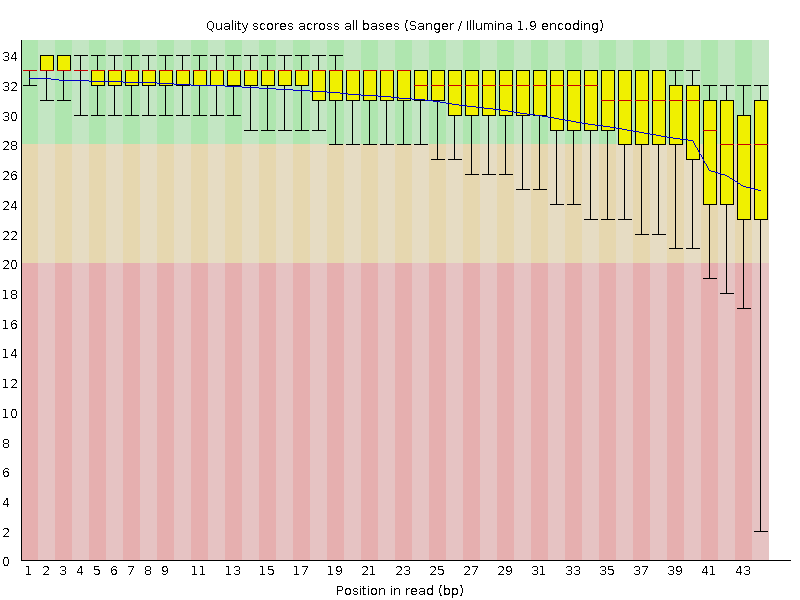

In [9]:
unzip -o -q fastqc/CEBPA_fastqc.zip -d fastqc
display < fastqc/CEBPA_fastqc/Images/per_base_quality.png

The quality is good for most of the read: up to position ~ 35 the median quality (red line) is above 30 (green part of the plot). Towards the end of the reads the quality drops (median ~ 28 for the last bases, and some reads have very low quality bases). This is typical for Illumina sequencing, and especially for older sequencers such as the Genome Analyzer II used here. The aligner can deal with a few low quality bases (they will be counted as mismatches), so we don't trim the reads.

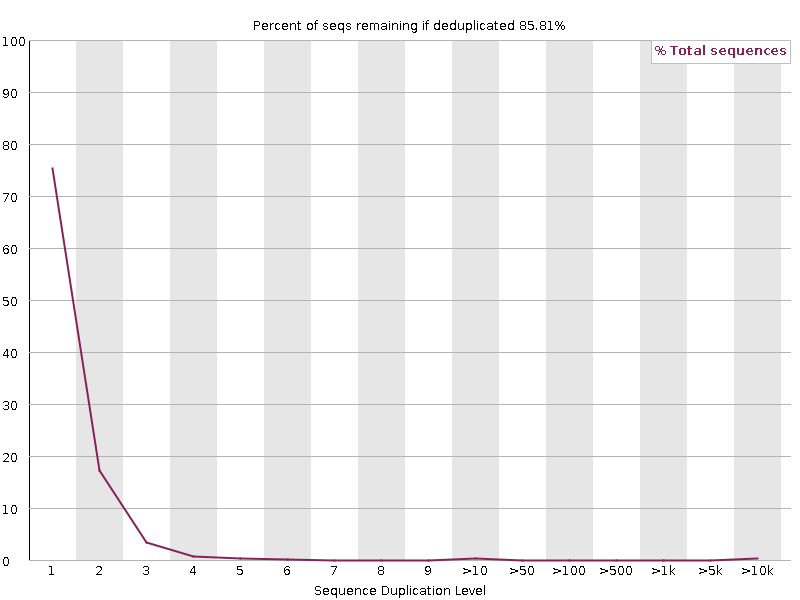

In [10]:
display < fastqc/CEBPA_fastqc/Images/duplication_levels.png

86% of the reads would remain after removing duplicates (title of the plot) and most sequences occur only once: the library has a high complexity, as expected for a good ChIP-seq library. (FastQC bases this estimate on the first 100,000 reads; we will remove duplicates properly after alignment, in Step 4.)

FastQC also gives a summary of all modules (PASS, WARN or FAIL):

In [11]:
paste fastqc/CEBPA_fastqc/summary.txt <(unzip -p fastqc/Input_fastqc.zip Input_fastqc/summary.txt | cut -f 1) \
    | awk -F '\t' 'BEGIN {print "CEBPA\tInput\tModule"} {print $1"\t"$4"\t"$2}' \
    | column -t -s $'\t'

CEBPA  Input  Module


PASS   PASS   Basic Statistics


PASS   PASS   Per base sequence quality


PASS   PASS   Per tile sequence quality


PASS   PASS   Per sequence quality scores


...

PASS   PASS   Per base N content


PASS   PASS   Sequence Length Distribution


PASS   PASS   Sequence Duplication Levels


WARN   WARN   Overrepresented sequences


PASS   PASS   Adapter Content


**Question**: Look at the "Per base sequence content" and "Overrepresented sequences" modules in the html reports. Are there adapters in the reads? Do you think we need to trim the reads before alignment? (Hint: how long are the reads compared to the size of the DNA fragments, ~ 200 bp?)

[MultiQC](https://multiqc.info/) collects the results of many tools (FastQC, Bowtie2, samtools, MACS, ...) in a single report. This is very useful when you have many samples.

In [12]:
# -f: overwrite existing reports, -o: output directory
multiqc -f -o multiqc_fastqc fastqc 2> /dev/null
# Total Sequences, percentage of reads left after removing duplicates, average and median read length
cut -f 1,5,10,11,12 multiqc_fastqc/multiqc_data/multiqc_fastqc.txt | column -t -s $'\t'

Sample  Total Sequences  total_deduplicated_percentage  avg_sequence_length  median_sequence_length


CEBPA   7209060.0        85.81216517795319              44.0                 44


Input   4566628.0        94.15884835055147              44.0                 44


## Step 3: aligning reads to a reference genome

Next we align the reads to the human genome. ChIP-seq reads come from genomic DNA, so (unlike RNA-seq) we don't need a *splice aware* aligner. We will use [Bowtie2](https://bowtie-bio.sourceforge.net/bowtie2/manual.shtml), a fast aligner for short DNA reads. [BWA](https://github.com/lh3/bwa) is a popular alternative.

Bowtie2 needs an *index* of the reference genome: a compressed data structure (based on the Burrows-Wheeler transform) that allows it to search the genome very quickly. We use the existing hg38 index of iGenomes. Building such an index yourself takes ~ 1-2 hours using 8 threads, starting from a fasta file of the genome:

    bowtie2-build --threads 8 genome.fa genome

The index consists of 6 files (`.bt2`), the common prefix (`genome`) is given to bowtie2 using `-x`. Let's have a look at the chromosomes in this genome:

In [13]:
grep ">" ${BOWTIE2_INDEX}.fa | head -n 30 | tr '\n' ' '
echo
echo "Number of sequences: $(grep -c ">" ${BOWTIE2_INDEX}.fa)"

>chr1 >chr2 >chr3 >chr4 >chr5 >chr6 >chr7 >chr8 >chr9 >chr10 >chr11 >chr12 >chr13 >chr14 >chr15 >chr16 >chr17 >chr18 >chr19 >chr20 >chr21 >chr22 >chrX >chrY >chrM >chr1_KI270706v1_random >chr1_KI270707v1_random >chr1_KI270708v1_random >chr1_KI270709v1_random >chr1_KI270710v1_random 


Number of sequences: 195


Besides the 24 chromosomes and the mitochondrial genome (chrM), the genome contains *unplaced* (`chrUn_...`) and *unlocalized* (`..._random`) contigs: sequences that are known to be part of the human genome, but could not be placed on a chromosome. This version of the genome does not contain *alternative haplotypes* (`_alt` contigs). Alternative haplotypes are (nearly) identical to the corresponding region of the main chromosome, so reads would map to two locations and be discarded as "not unique".

Let's first test bowtie2 on the first 10,000 reads of the CEBPA sample.

In [14]:
mkdir -p alignment_test
zcat fastq_files/CEBPA.fastq.gz | head -n 40000 > alignment_test/CEBPA_10000.fastq
# -x: prefix of the genome index
# -U: fastq file with unpaired (single-end) reads
# -S: output SAM file
# -p 8: use 8 threads
bowtie2 -p 8 -x ${BOWTIE2_INDEX} -U alignment_test/CEBPA_10000.fastq -S alignment_test/CEBPA_10000.sam

10000 reads; of these:


  10000 (100.00%) were unpaired; of these:


    1505 (15.05%) aligned 0 times


    5933 (59.33%) aligned exactly 1 time


    2562 (25.62%) aligned >1 times


84.95% overall alignment rate


Bowtie2 prints a summary of the alignment:

- **aligned 0 times**: reads that could not be aligned (e.g. low quality reads, contamination, sequences not in the reference genome)
- **aligned exactly 1 time**: reads that map to a single location in the genome
- **aligned >1 times**: reads that map to multiple locations, for example reads in repeats. Bowtie2 reports only one (randomly chosen) location for these reads, and gives them a low mapping quality (see below).

The alignment is stored in a SAM file. The SAM file starts with a header section, the headings always begin with the "@" symbol. The `@SQ` lines list all sequences (chromosomes) of the reference genome and their length, the `@PG` line shows the command that was used to generate the file.

In [15]:
grep "^@" alignment_test/CEBPA_10000.sam | head -n 5
# the @PG line contains the full location of bowtie2 and of the genome index, we print ${CHIPSEQ_ENV} and ${GENOME_DIR} instead to keep it short
grep "^@PG" alignment_test/CEBPA_10000.sam | sed "s|${CHIPSEQ_ENV}|\${CHIPSEQ_ENV}|g; s|${GENOME_DIR}|\${GENOME_DIR}|g"

@HD	VN:1.5	SO:unsorted	GO:query


@SQ	SN:chr1	LN:248956422


@SQ	SN:chr2	LN:242193529


@SQ	SN:chr3	LN:198295559


@SQ	SN:chr4	LN:190214555


@PG	ID:bowtie2	PN:bowtie2	VN:2.5.4	CL:"${CHIPSEQ_ENV}/bin/bowtie2-align-s --wrapper basic-0 -p 8 -x ${GENOME_DIR}/indexes/Bowtie2/genome -S alignment_test/CEBPA_10000.sam -U alignment_test/CEBPA_10000.fastq"


In [16]:
grep -v "^@" alignment_test/CEBPA_10000.sam | head -n 520 | tail -n 4

ERR235723.533	16	chr8	8127623	1	44M	*	0	0	GTGCCAGGCACTGTGCTGTGTTGCGGGAAGTCAGGGACCCCAAA	A7==;6@A94AAABB@AABB;@@ABB@BAA<?@ABB8AABBBBB	AS:i:0	XS:i:0	XN:i:0	XM:i:0	XO:i:0	XG:i:0	NM:i:0	MD:Z:44	YT:Z:UU


ERR235723.534	16	chr4	98468766	42	44M	*	0	0	TCTGGCCATGAAACCCTGCTGGCCAGCGTTTATAGAGGGCTTCC	::8@B?799AA@5BBAABBABCBBACBA=?BBCBCBCCCA=@AB	AS:i:0	XN:i:0	XM:i:0	XO:i:0	XG:i:0	NM:i:0	MD:Z:44	YT:Z:UU


ERR235723.535	0	chr13	31605356	42	44M	*	0	0	ACAATTGAACAAAAAATGTAAAGACACATTAAGACAGATATGGT	BBBCBBBBCBBBAA>BBB=BB@ABBBBAAAAA?ABA??>??@>6	AS:i:0	XN:i:0	XM:i:0	XO:i:0	XG:i:0	NM:i:0	MD:Z:44	YT:Z:UU


ERR235723.536	0	chr8	22228343	42	44M	*	0	0	GGACAGCAGCTCCATGCTCCCGTCAGGGTTGTCTCCTGTGGGGA	BBBB?@BBABBBBBBAB@BBBB9@;>>98?A9B9B@3=7>==8#	AS:i:0	XN:i:0	XM:i:0	XO:i:0	XG:i:0	NM:i:0	MD:Z:44	YT:Z:UU


The alignment section has 11 mandatory fields (columns) and each read is represented as a single row:

1. QNAME: query (read) name
2. FLAG: bitwise FLAG
3. RNAME: reference sequence name (chromosome)
4. POS: 1-based leftmost mapping position
5. MAPQ: mapping quality
6. CIGAR: CIGAR string (`44M`: all 44 bases are aligned)
7. RNEXT: chromosome of the mate (`*`: not applicable for single-end data)
8. PNEXT: position of the mate
9. TLEN: observed fragment (template) length (0 for single-end data: we don't know where the fragment ends!)
10. SEQ: read sequence (reverse complemented if the read maps to the reverse strand)
11. QUAL: base qualities

followed by optional fields (SAM tags) of the form `<TAG>:<type>:<value>`. For bowtie2, `AS:i` is the alignment score, `XS:i` the score of the second best alignment (only present for reads that map to multiple locations), `NM:i` the number of mismatches and `MD:Z` the positions of the mismatches.

**The bitwise FLAG** encodes several properties of the read as a sum of powers of 2. For single-end data there are only a few common flags:

| FLAG | meaning |
|---|---|
| 0 | read mapped to the forward strand |
| 16 | read mapped to the reverse strand |
| 4 | read unmapped |
| 256 | secondary alignment (not the best alignment of this read; not reported by bowtie2 by default) |
| 1024 | PCR or optical duplicate (set by `samtools markdup`, see Step 4) |

To decode a flag you can use `samtools flags`, or https://broadinstitute.github.io/picard/explain-flags.html

In [17]:
samtools flags 16
samtools flags UNMAP,SECONDARY

0x10	16	REVERSE


0x104	260	UNMAP,SECONDARY


**MAPQ** (mapping quality) is an estimate of the probability that the read is mapped to the wrong location: $MAPQ = -10 \log_{10}P$. For bowtie2 a MAPQ of 0 or 1 means that the read maps equally well to multiple locations. Reads that map uniquely (and without many mismatches) get a MAPQ of 23 - 42. Let's look at the distribution of mapping qualities in our test file.

In [18]:
# count how many reads have each MAPQ value (column 5), skip unmapped reads (-F 4)
samtools view -F 4 alignment_test/CEBPA_10000.sam | cut -f 5 | sort -n | uniq -c | sort -k1,1nr | head -n 12

   5798 42


   1164 1


    432 30


    154 39


    146 38


...

     96 37


     69 40


     61 32


     55 36


     33 26


**Question**: Look at the 4 reads shown above. On which strand do they map? Which of them would you trust and which not? Why?

Let's align all reads. SAM files are plain text files and take a lot of space, so we directly convert the output of bowtie2 into a *sorted* BAM file (a binary, compressed version of a SAM file) using `samtools sort`. The `|` (pipe) sends the output of bowtie2 directly to samtools, without writing a SAM file to disk. Aligning one sample takes ~ 1-2 minutes using 8 threads.

In [19]:
mkdir -p alignment
for sample in CEBPA Input
do
    echo "Aligning ${sample}"
    # 2> alignment/${sample}.bowtie2.log: save the summary (printed to stderr) in a log file
    # samtools sort -o: output file, -@ 4: use 4 extra threads, -: read from the pipe (standard input)
    bowtie2 -p 8 -x ${BOWTIE2_INDEX} -U fastq_files/${sample}.fastq.gz 2> alignment/${sample}.bowtie2.log \
        | samtools sort -@ 4 -o alignment/${sample}.sorted.bam -
    samtools index alignment/${sample}.sorted.bam
    cat alignment/${sample}.bowtie2.log
done

Aligning CEBPA


[bam_sort_core] merging from 0 files and 4 in-memory blocks...


7209060 reads; of these:


  7209060 (100.00%) were unpaired; of these:


    1083899 (15.04%) aligned 0 times


...

  4566628 (100.00%) were unpaired; of these:


    188851 (4.14%) aligned 0 times


    2966617 (64.96%) aligned exactly 1 time


    1411160 (30.90%) aligned >1 times


95.86% overall alignment rate


For both samples a large majority of the reads is aligned, but ~ 25-30% of the reads map to more than one location. The human genome contains many repeats (~ 50% of the genome!) and with short reads of 44 bp it is often impossible to know where a read in a repeat comes from.

The `.bai` file is the *index* of the BAM file: it allows programs (like IGV) to quickly find the reads in a given region without reading the whole file. Using samtools we can inspect BAM files. For example, `samtools flagstat` summarises the flags:

In [20]:
ls -lhgG alignment
samtools flagstat alignment/CEBPA.sorted.bam

total 554M


-rw-rw----+ 1  219 Oct 28 19:35 CEBPA.bowtie2.log


-rw-rw----+ 1 328M Oct 28 19:35 CEBPA.sorted.bam


-rw-rw----+ 1 4.2M Oct 28 19:35 CEBPA.sorted.bam.bai


-rw-rw----+ 1  217 Oct 28 19:36 Input.bowtie2.log


...

0 + 0 properly paired (N/A : N/A)


0 + 0 with itself and mate mapped


0 + 0 singletons (N/A : N/A)


0 + 0 with mate mapped to a different chr


0 + 0 with mate mapped to a different chr (mapQ>=5)


And `samtools idxstats` shows how many reads mapped to each chromosome:

In [21]:
# columns: chromosome name, chromosome length, number of mapped reads, number of unmapped reads
samtools idxstats alignment/CEBPA.sorted.bam | head -n 25

chr1	248956422	549688	0


chr2	242193529	481310	0


chr3	198295559	390818	0


chr4	190214555	341688	0


chr5	181538259	347418	0


...

chr21	46709983	91233	0


chr22	50818468	101333	0


chrX	156040895	164459	0


chrY	57227415	50480	0


chrM	16569	45399	0


## Step 4: filtering the alignments

Before peak calling we remove reads that are not informative or can cause false positive peaks:

1. **Unmapped reads** (flag 4) and **reads with a low mapping quality** (MAPQ < 30): we don't know where multi-mapping reads come from. If we would keep them, repeats could show up as peaks.
2. **Duplicates**: reads that start at exactly the same position on the same strand. Most of these are copies of the same DNA fragment made during PCR amplification of the library (*PCR duplicates*), not independent fragments. They would give extra (artificial) weight to some fragments.

Let's first filter on mapping quality.

In [22]:
for sample in CEBPA Input
do
    # -b: output BAM, -F 4: exclude unmapped reads, -q 30: keep reads with MAPQ >= 30
    samtools view -b -F 4 -q 30 -@ 4 -o alignment/${sample}.q30.bam alignment/${sample}.sorted.bam
done

Next, we mark and remove duplicates using `samtools markdup`. The file must be sorted by position (which is the case).

In [23]:
for sample in CEBPA Input
do
    # -r: remove duplicates (instead of only marking them with flag 1024)
    # -s: print statistics, -f: write the statistics to a file
    samtools markdup -r -s -f alignment/${sample}.markdup.txt -@ 4 alignment/${sample}.q30.bam alignment/${sample}.filtered.bam 2> /dev/null
    samtools index alignment/${sample}.filtered.bam
done
cat alignment/CEBPA.markdup.txt

COMMAND: samtools markdup -r -s -f alignment/CEBPA.markdup.txt -@ 4 alignment/CEBPA.q30.bam alignment/CEBPA.filtered.bam


READ: 5019771


WRITTEN: 4348685


EXCLUDED: 0


EXAMINED: 5019771


...

DUPLICATE NON PRIMARY: 0


DUPLICATE NON PRIMARY OPTICAL: 0


DUPLICATE PRIMARY TOTAL: 671086


DUPLICATE TOTAL: 671086


ESTIMATED_LIBRARY_SIZE: 0


Let's compare the number of reads after each step.

In [24]:
echo -e "sample\tall_reads\tmapped\tMAPQ>=30\tno_duplicates"
for sample in CEBPA Input
do
    echo -e "${sample}\t$(samtools view -c alignment/${sample}.sorted.bam)\t$(samtools view -c -F 4 alignment/${sample}.sorted.bam)\t$(samtools view -c alignment/${sample}.q30.bam)\t$(samtools view -c alignment/${sample}.filtered.bam)"
done | column -t

sample	all_reads	mapped	MAPQ>=30	no_duplicates


CEBPA  7209060  6125161  5019771  4348685


Input  4566628  4377777  3523028  3429326


The intermediate BAM file with only the MAPQ filter is not needed anymore.

In [25]:
rm alignment/*.q30.bam
ls -lhgG alignment

total 938M


-rw-rw----+ 1  219 Oct 28 19:35 CEBPA.bowtie2.log


-rw-rw----+ 1 209M Oct 28 19:36 CEBPA.filtered.bam


-rw-rw----+ 1 4.3M Oct 28 19:36 CEBPA.filtered.bam.bai


-rw-rw----+ 1  446 Oct 28 19:36 CEBPA.markdup.txt


...

-rw-rw----+ 1 167M Oct 28 19:36 Input.filtered.bam


-rw-rw----+ 1 4.5M Oct 28 19:36 Input.filtered.bam.bai


-rw-rw----+ 1  443 Oct 28 19:36 Input.markdup.txt


-rw-rw----+ 1 218M Oct 28 19:36 Input.sorted.bam


-rw-rw----+ 1 4.4M Oct 28 19:36 Input.sorted.bam.bai


**Question**: Removing duplicates is standard for ChIP-seq, but it is usually *not* done for RNA-seq. Why? (Hint: think about a very highly expressed gene. Would you expect reads that start at the same position?)

**Question**: Why is it more important to remove duplicates for single-end data than for paired-end data? (Hint: for paired-end data, when are two read pairs considered duplicates?)

**Question**: Why do you think the Input has a lower fraction of duplicates than the CEBPA ChIP?

## Step 5: visualize the alignments in a genome browser (IGV)

The aligned reads can be visualized in a genome browser, for example [IGV](https://igv.org/). Download `CEBPA.filtered.bam` and `CEBPA.filtered.bam.bai` to your computer and open them with IGV (make sure the genome is set to hg38). Go to `CYP2E1` (type the gene name in the search box and press "Go"). CYP2E1 is a cytochrome P450 enzyme that metabolises drugs and toxins (e.g. ethanol and paracetamol) in the liver, and a target gene of CEBPA. You will see an enrichment of reads, a "peak", at the promoter of this gene.

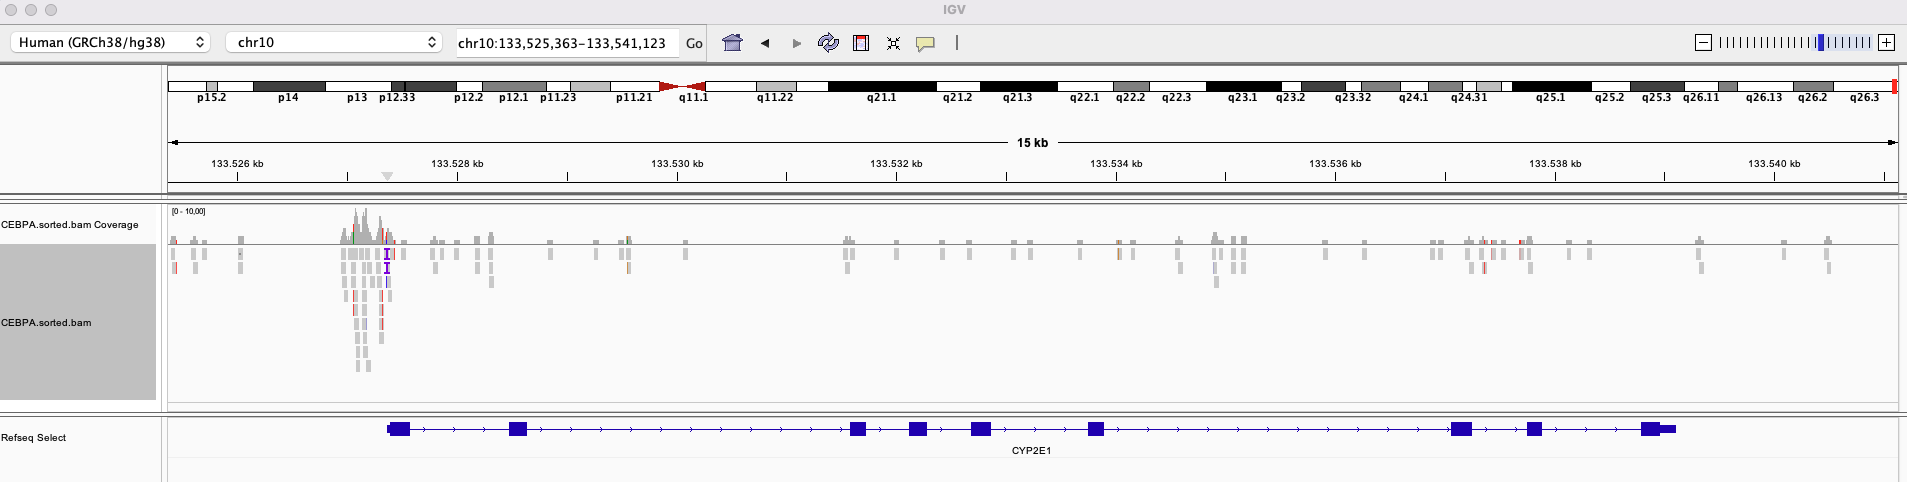

Now also load the Input BAM file. At the CYP2E1 promoter there is no enrichment of reads in the Input.

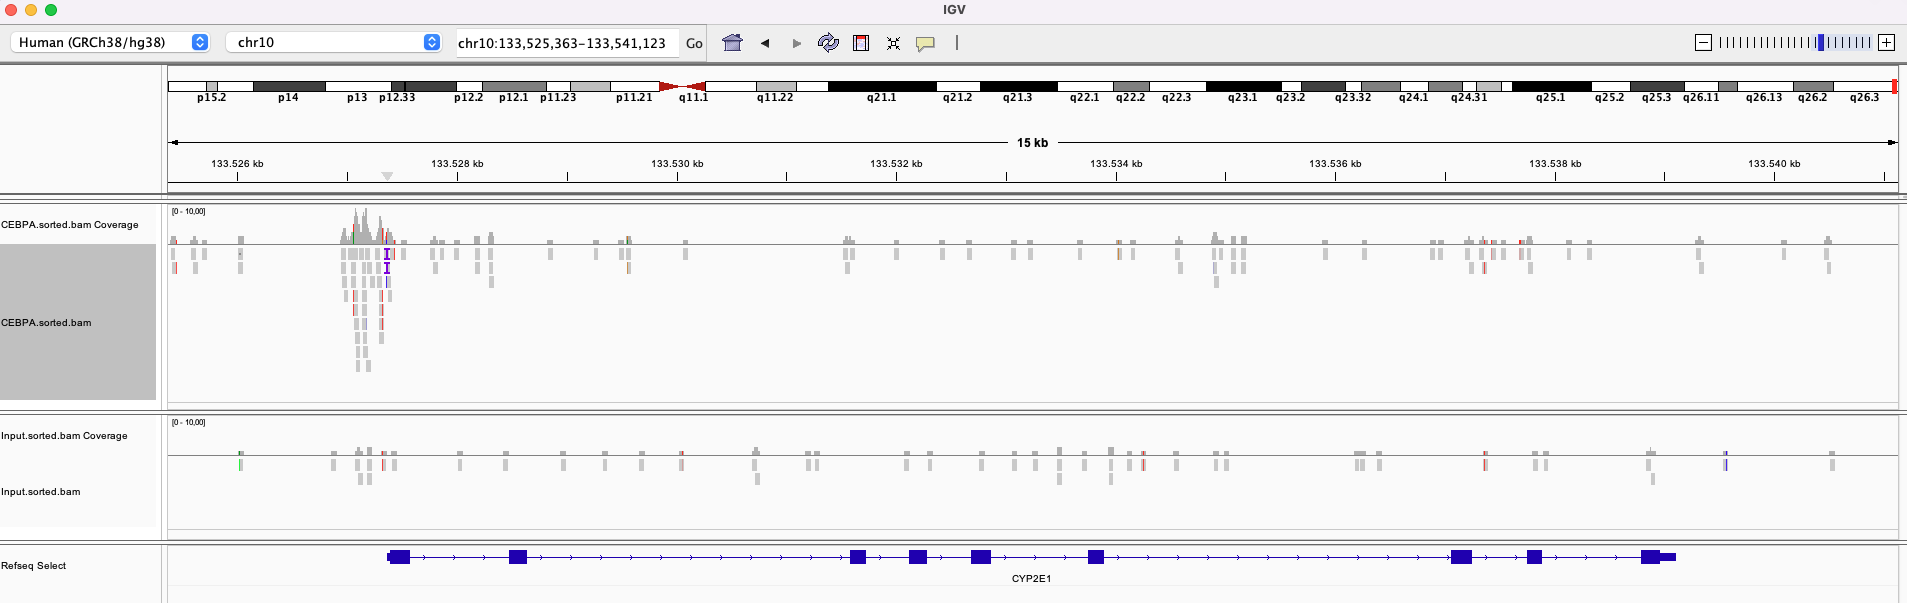

**Note**: these screenshots show the BAM files before filtering (`CEBPA.sorted.bam`), your filtered BAM files will have slightly fewer reads.

**Question**: Zoom in on a peak until you see individual reads. What do you notice about the strand of the reads on the left and on the right side of the peak? (IGV: right click > Color alignments by > read strand). We will come back to this in Step 7.

## Step 6: genome-wide coverage tracks and ChIP quality

BAM files are large and contain every single read. For visualisation we usually create a **bigWig** file: it only contains the *coverage* (the number of reads overlapping each region of the genome, in bins of e.g. 50 bp). bigWig files are much smaller and faster to load. They can be opened in IGV, and also as custom track in the UCSC genome browser (provided that the bigWig is available on a web server, so you can specify the custom track by entering the URL).

We use `bamCoverage` of [deepTools](https://deeptools.readthedocs.io/). Some important options:

- `--binSize 50`: compute the coverage in bins of 50 bp (a smaller bin size gives more detail but a larger file).
- `--extendReads 200`: a read only covers the first 44 bp of a DNA fragment of ~ 200 bp. With this option each read is extended to 200 bp in the direction of the read, so the coverage reflects the full fragment (see Step 7).
- `--normalizeUsing RPGC`: normalize to 1x coverage (*reads per genomic content*). This makes samples with a different number of reads comparable. For this we need the *effective genome size*: the part of the genome to which reads can be mapped uniquely. For hg38 and reads of ~ 50 bp this is 2,701,495,761 bp (see the [deepTools documentation](https://deeptools.readthedocs.io/en/latest/content/feature/effectiveGenomeSize.html)).

This takes ~ 30 seconds per sample.

In [26]:
mkdir -p bigwig
for sample in CEBPA Input
do
    # -p 8: use 8 threads
    bamCoverage \
        -b alignment/${sample}.filtered.bam \
        -o bigwig/${sample}.bw \
        --binSize 50 \
        --extendReads 200 \
        --normalizeUsing RPGC \
        --effectiveGenomeSize 2701495761 \
        -p 8 2> /dev/null
done
ls -lhgG bigwig

total 57M


-rw-rw----+ 1 36M Oct 28 19:37 CEBPA.bw


-rw-rw----+ 1 30M Oct 28 19:37 Input.bw


The bigWig files are ~ 10x smaller than the BAM files. We can open them in IGV (screenshot made with bigWigs of a previous version of this practical with a bin size of 50 bp (red) and 5 bp (green)):

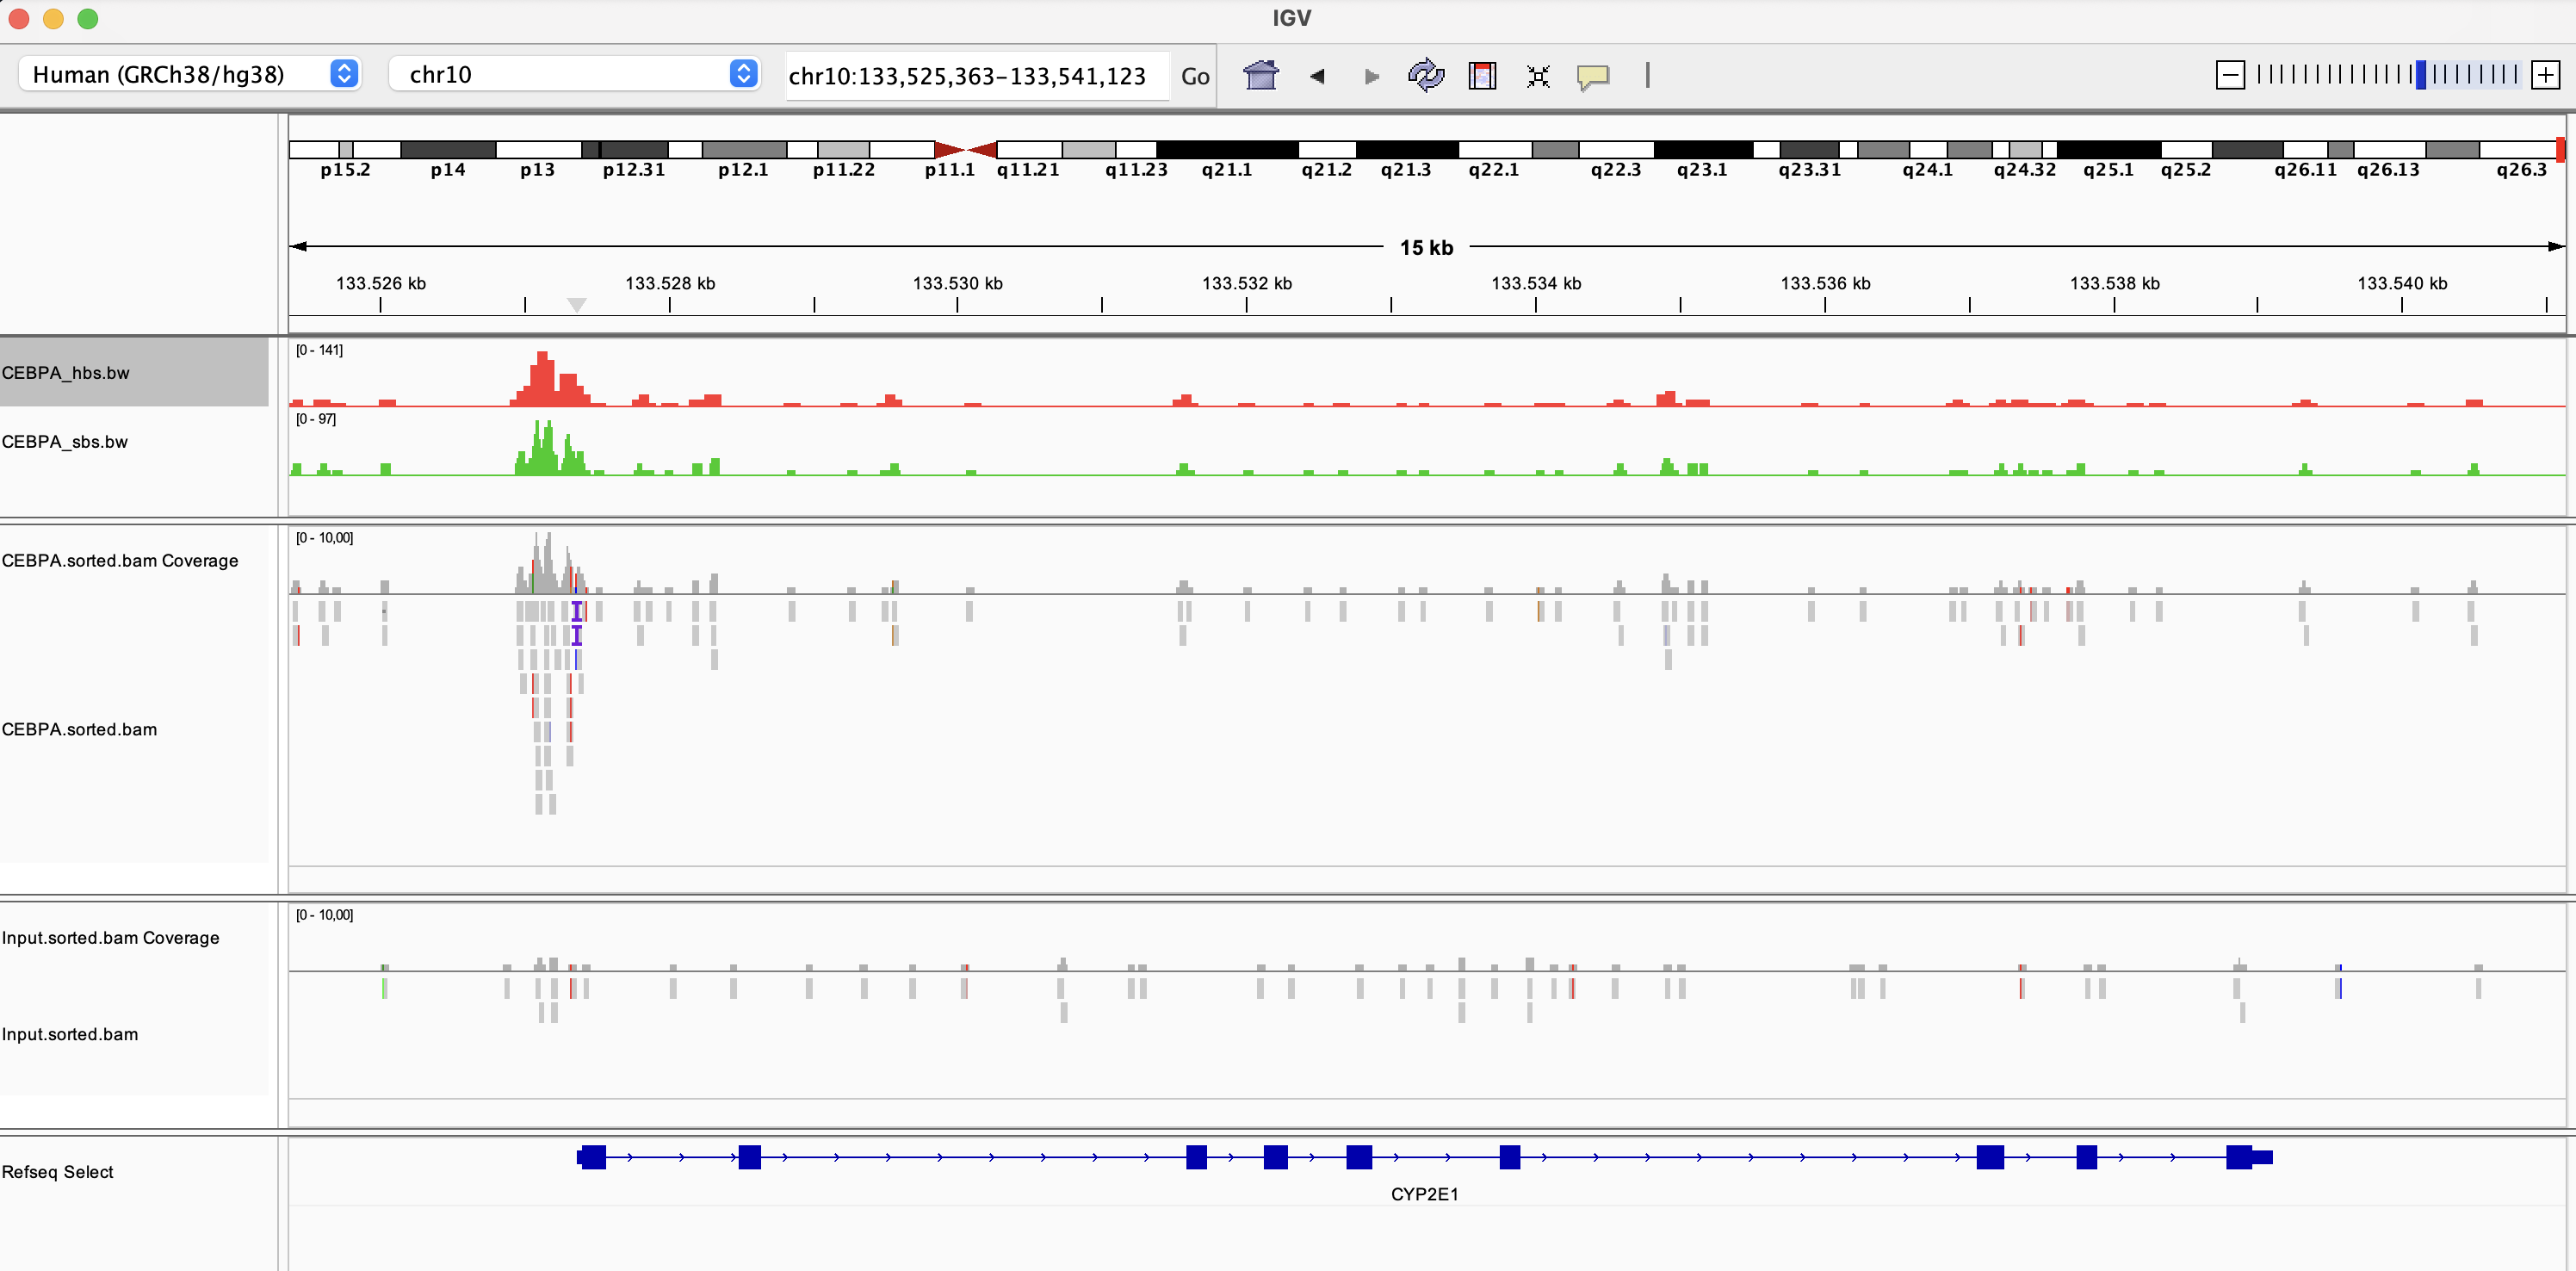

### How enriched is our ChIP?

Not every ChIP works equally well, this depends a lot on the quality of the antibody. A useful quality check is the **fingerprint plot** of deepTools (`plotFingerprint`). The genome is divided into bins, the reads per bin are counted and the bins are sorted from low to high coverage. The plot shows the cumulative fraction of reads as a function of the fraction of bins (the "rank").

- For an Input sample, reads are spread (almost) uniformly over the genome: the curve is close to the diagonal.
- For a good ChIP, a large fraction of the reads is concentrated in a small fraction of the genome (the peaks): the curve stays low for a long time and rises sharply at the end.

This takes ~ 1 minute.

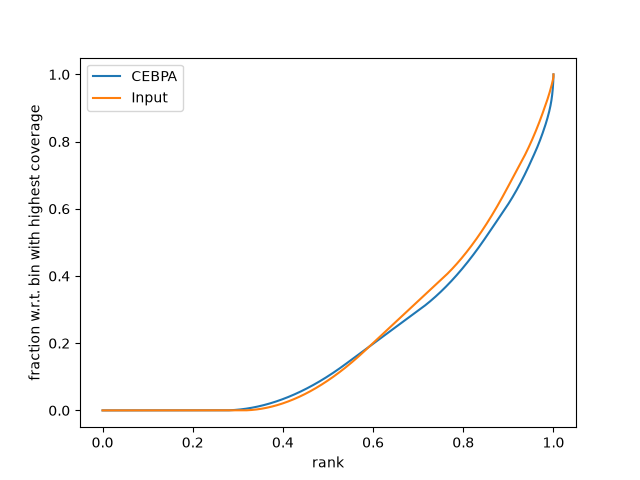

In [27]:
mkdir -p qc
plotFingerprint \
    -b alignment/CEBPA.filtered.bam alignment/Input.filtered.bam \
    --labels CEBPA Input \
    --extendReads 200 \
    --skipZeros \
    --numberOfSamples 500000 \
    -p 8 \
    --plotFile qc/fingerprint.png \
    --outQualityMetrics qc/fingerprint_metrics.txt 2> /dev/null
display < qc/fingerprint.png

In [28]:
# AUC: area under the curve, X-intercept: fraction of bins without reads, Elbow Point: rank at which the curve rises most steeply
cut -f 1,2,4,6 qc/fingerprint_metrics.txt | column -t -s $'\t'

Sample  AUC                  X-intercept         Elbow Point


CEBPA   0.2101020151888398   0.2681641026234546  0.7060469368918415


Input   0.22147945468696792  0.3087470668059361  0.5220665889303933


The CEBPA curve is only slightly different from the Input curve: it is a bit lower in the middle and rises more steeply at the very end (the *elbow point* lies further to the right: 0.71 versus 0.52). Both curves start rising at ~ 0.3: ~ 30% of the bins contain no reads at all, because the sequencing depth is low (~ 4 million reads for 3 billion bases).

The difference is small because a TF binds only a tiny part of the genome, and most reads of a TF ChIP-seq experiment are background (we will see in Step 7 that only ~ 6% of the CEBPA reads are in peaks). For a histone mark such as H3K27ac (Step 8.6), which covers a much larger part of the genome, the difference with the Input is usually much clearer. For TF ChIP-seq the fingerprint is only a rough check, the fraction of reads in peaks (FRiP, Step 7) and the number of peaks are more informative.

**Question**: Compare the curves with the examples in the [deepTools documentation](https://deeptools.readthedocs.io/en/latest/content/tools/plotFingerprint.html). For a TF, only a tiny fraction of the genome is bound (~ 10,000 sites of a few hundred bp). What fraction of the genome is that?

## Step 7: peak calling

Next, we determine the genomic regions with an enrichment of reads: the **peaks**.

Figure from this article: http://journals.plos.org/plosone/article?id=10.1371/journal.pone.0011471

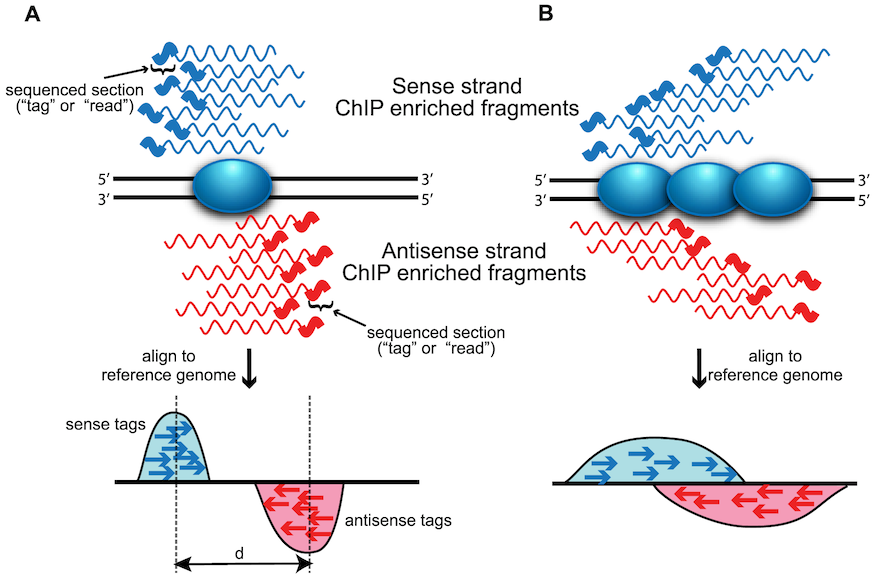

<i>Figure caption from the paper:
Strand-dependent bimodality in tag density.
The 5′ to 3′ sequencing requirement and short read length produce stranded bias in tag distribution. The shaded blue oval represents the protein of interest bound to DNA (solid black lines). Wavy lines represent either sense (blue) or antisense (red) DNA fragments from ChIP enrichment. The thicker portion of the line indicates regions sequenced by short read sequencing technologies. Sequenced tags are aligned to a reference genome and projected onto a chromosomal coordinate (red and blue arrows). (A) Sequence-specific binding events (e.g. transcription factors) are characterized by "punctuate enrichment" and defined strand-dependent bimodality, where the separation between peaks (d) corresponds to the average sequenced fragment length. Panel A was inspired by Jothi et al. (B) Distributed binding events (e.g. histones or RNA polymerase) produce a broader pattern of tag enrichment that results in a less defined bimodal pattern.</i>

Because we only sequence the first 44 bp of each fragment, reads on the forward strand pile up on the left of the binding site and reads on the reverse strand on the right. The binding site itself is in the middle.

If you color the reads by strand in IGV (right click > Color alignments by > read strand), you will notice the shift between forward (red) and reverse (blue) reads. Example around APOC1 (an apolipoprotein made by the liver, another CEBPA target gene):

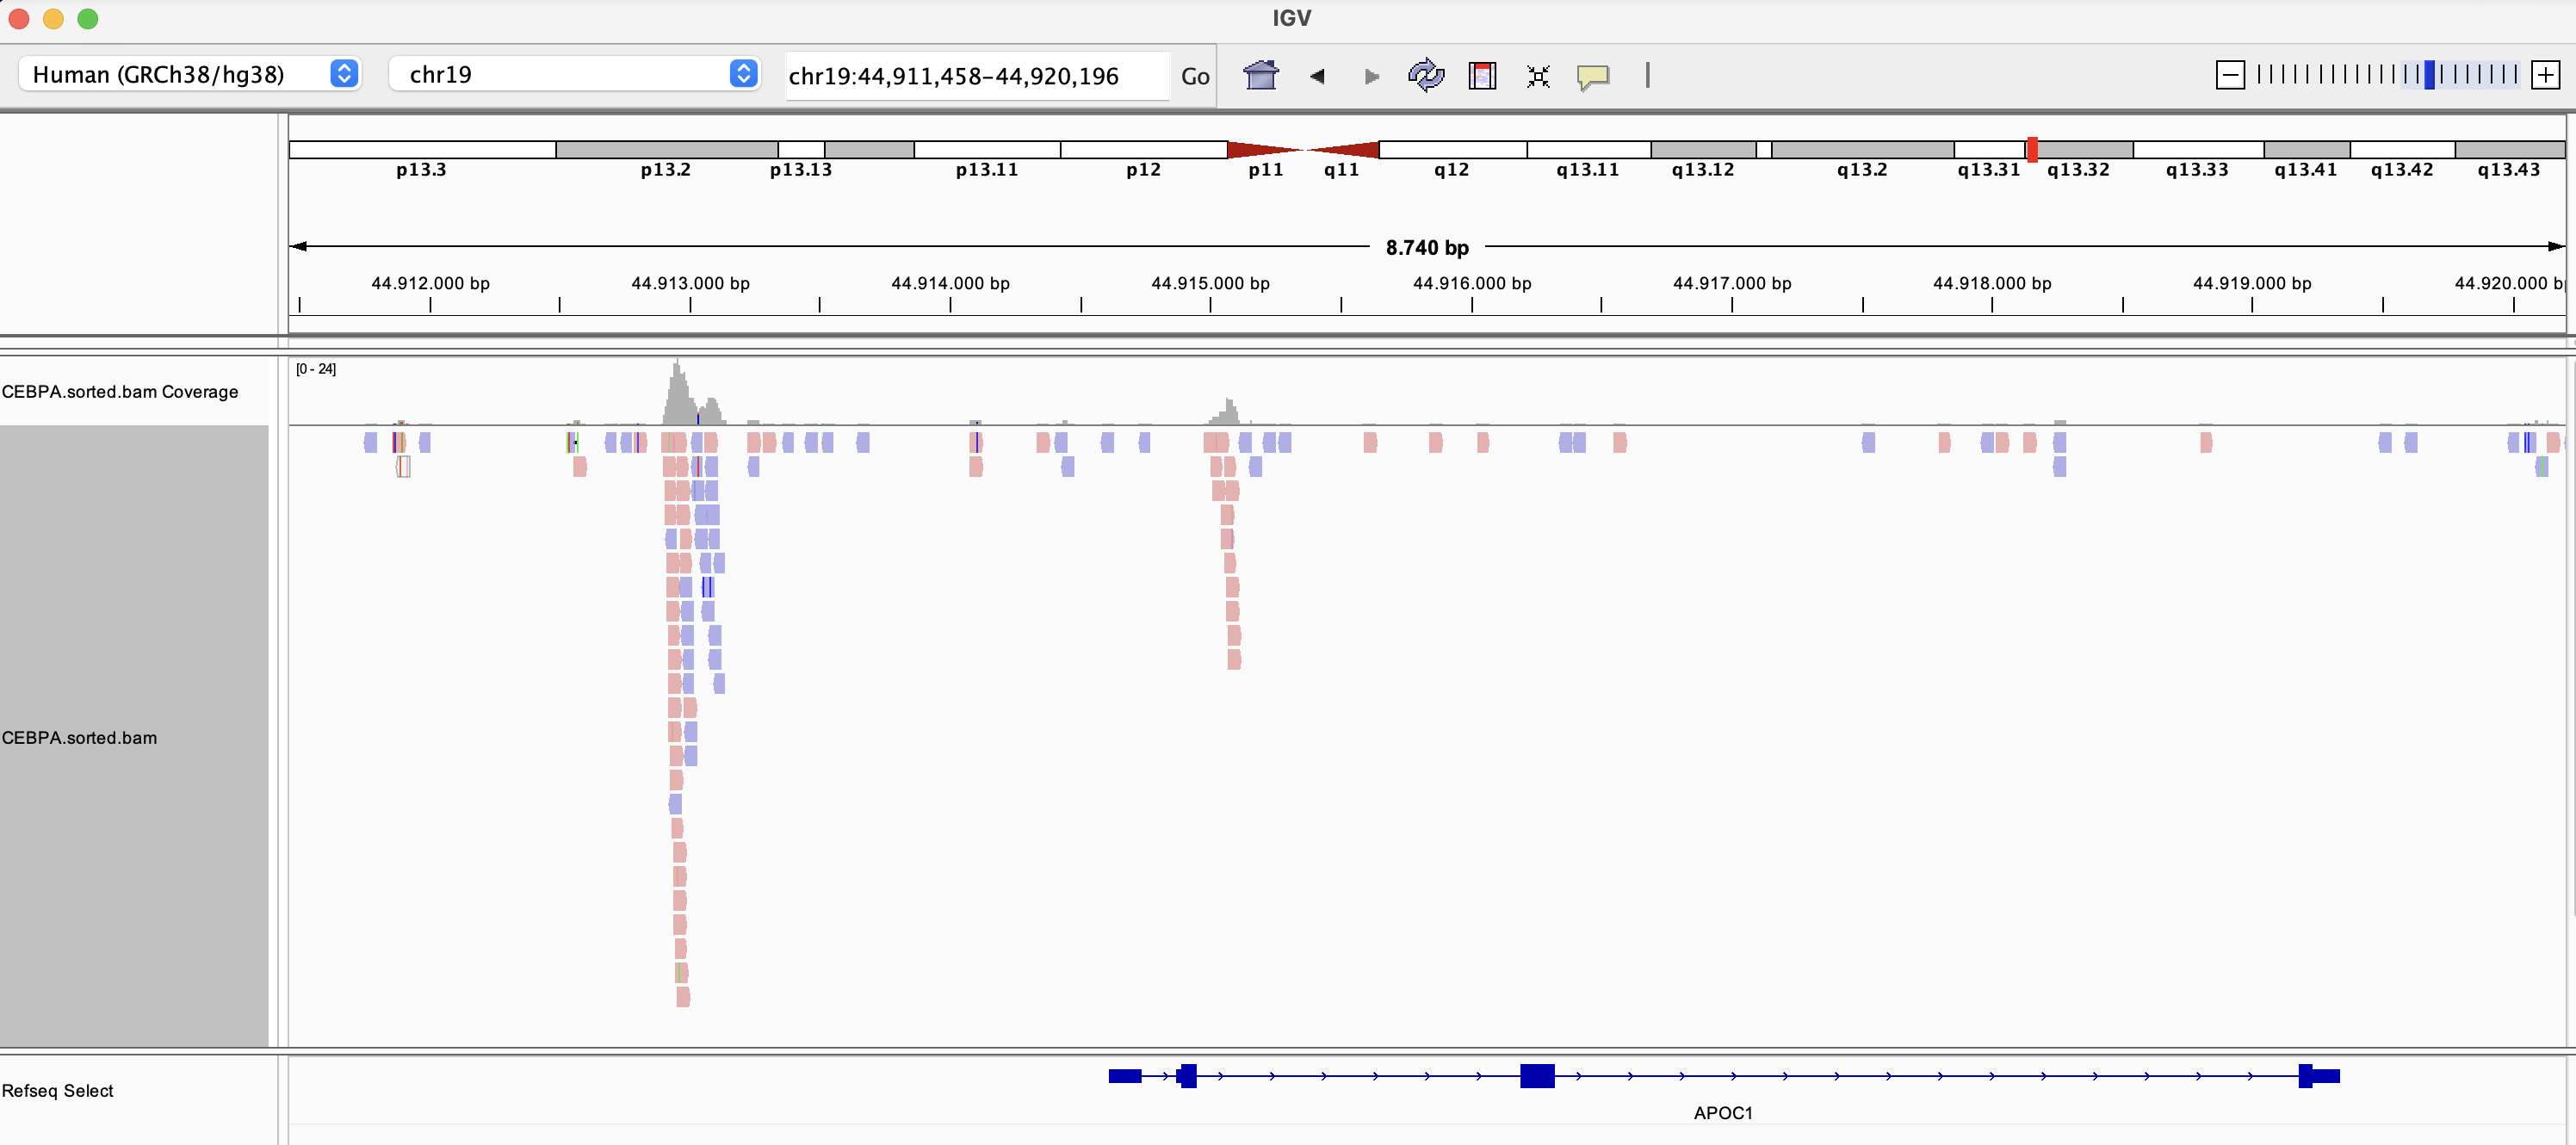

You can also separate them (right click > Group alignments by > read strand). Examples around the APOC1 and CSF3R genes:

APOC1

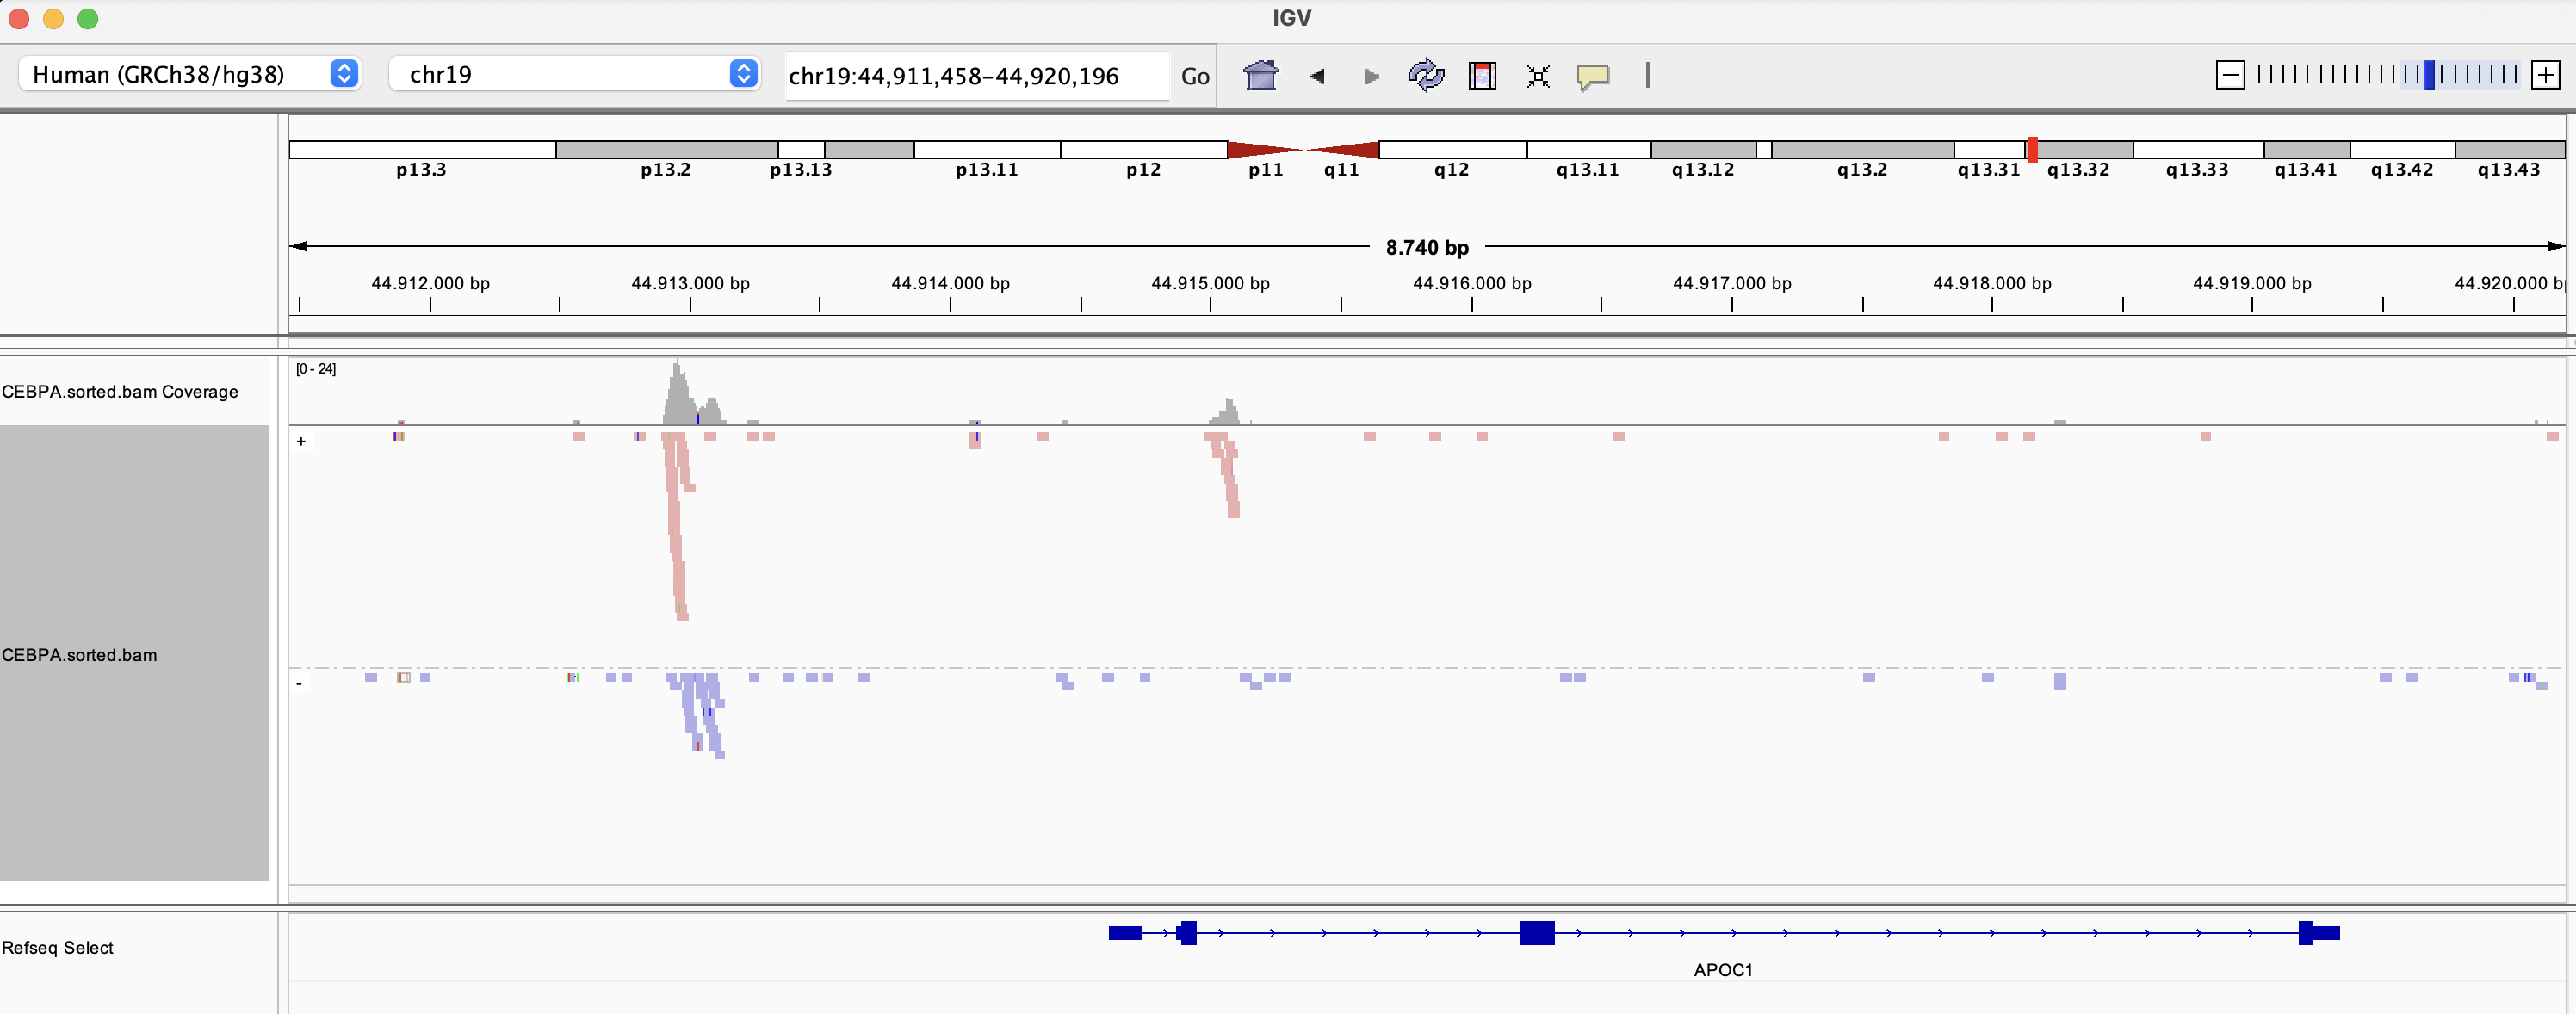

CSF3R (the receptor of the cytokine G-CSF, which is essential for the production of neutrophils; a well known CEBPA target in the myeloid lineage)

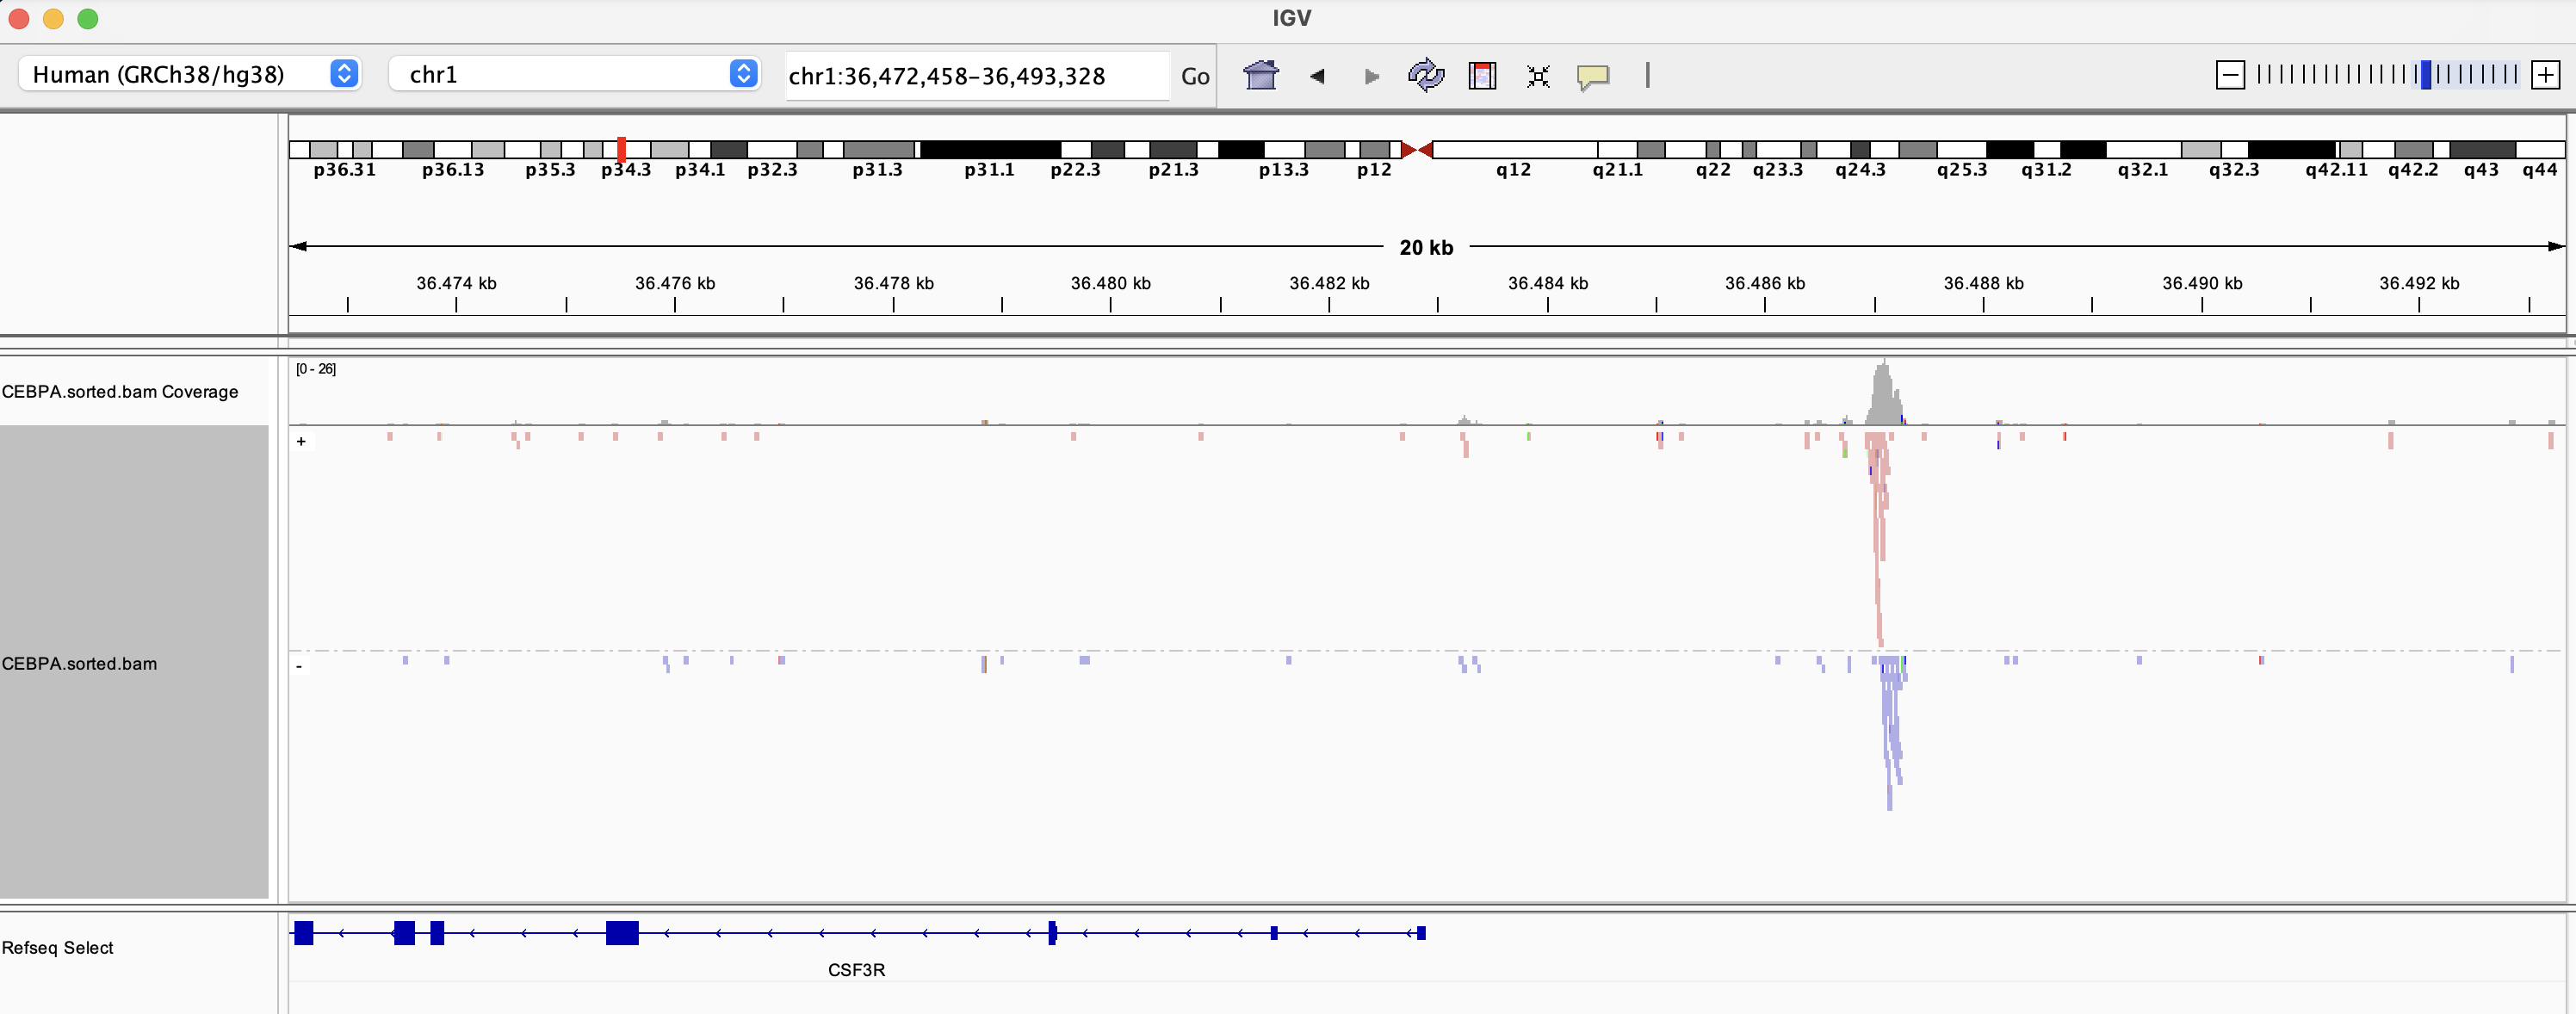

### Peak calling with MACS3

[MACS](https://macs3-project.github.io/MACS/) (Model-based Analysis of ChIP-Seq) is the most widely used peak caller. It works in a few steps:

1. **Model the fragment length**: MACS finds a number of strongly enriched regions and measures the distance *d* between the summit of the forward reads and the summit of the reverse reads (see the figure above). This distance is the average fragment length. Each read is then shifted by d/2 towards the binding site (or, equivalently, extended to a fragment of length d).
2. **Local background**: for each position MACS estimates the expected number of reads (lambda) from the Input, in windows of 1 kb, 5 kb and 10 kb around the position (and the genome wide average). The largest of these values is used. This corrects for local biases, such as copy number gains or open chromatin, that are also present in the Input.
3. **Test for enrichment**: using a Poisson distribution with this local lambda, MACS computes a p-value for the number of ChIP reads at each position. Regions with a significant enrichment are called peaks, p-values are corrected for multiple testing (q-values, Benjamini-Hochberg).

Important options:

- `-t`: treatment (ChIP) file, `-c`: control (Input) file
- `-f BAM`: format of the input files
- `-g hs`: effective genome size, `hs` is a shortcut for the human genome
- `-n CEBPA`: name (prefix) of the output files, `--outdir`: output folder
- `-q 0.05`: q-value (FDR) cutoff

This takes less than a minute.

In [29]:
macs3 callpeak \
    -t alignment/CEBPA.filtered.bam \
    -c alignment/Input.filtered.bam \
    -f BAM \
    -g hs \
    -n CEBPA \
    --outdir peaks \
    -q 0.05 2> peaks.CEBPA.log
tail -n 25 peaks.CEBPA.log

INFO  @ 28 Oct 2026 19:38:12: [167 MB] #1  tags after filtering in treatment: 4348651 


INFO  @ 28 Oct 2026 19:38:12: [167 MB] #1  Redundant rate of treatment: 0.00 


INFO  @ 28 Oct 2026 19:38:12: [167 MB] #1  total tags in control: 3429326 


INFO  @ 28 Oct 2026 19:38:12: [167 MB] #1 user defined the maximum tags... 


INFO  @ 28 Oct 2026 19:38:12: [167 MB] #1 filter out redundant tags at the same location and the same strand by allowing at most 1 tag(s) 


...

INFO  @ 28 Oct 2026 19:38:12: [170 MB] Peak process backend: fork, workers=7 


INFO  @ 28 Oct 2026 19:38:12: [170 MB] #4 Write output xls file... peaks/CEBPA_peaks.xls 


INFO  @ 28 Oct 2026 19:38:12: [170 MB] #4 Write peak in narrowPeak format file... peaks/CEBPA_peaks.narrowPeak 


INFO  @ 28 Oct 2026 19:38:12: [170 MB] #4 Write summits bed file... peaks/CEBPA_summits.bed 


INFO  @ 28 Oct 2026 19:38:12: [170 MB] Done! 


In [30]:
ls -lhgG peaks

total 2.0K


-rw-rw----+ 1  98K Oct 28 19:38 CEBPA_model.r


-rw-rw----+ 1 1.1M Oct 28 19:38 CEBPA_peaks.narrowPeak


-rw-rw----+ 1 1.2M Oct 28 19:38 CEBPA_peaks.xls


-rw-rw----+ 1 681K Oct 28 19:38 CEBPA_summits.bed


MACS3 produces the following files:

* `CEBPA_peaks.xls`: a tab separated file (despite the extension it is not an Excel file, but you can open it in Excel) with information about the called peaks: position, length, height (pileup), fold enrichment, p- and q-value, and at the top a summary of the parameters and the model.
* `CEBPA_peaks.narrowPeak`: BED6+4 format file with the peak locations together with peak summit, fold enrichment, p-value and q-value. You can load it directly in IGV or the UCSC genome browser.
* `CEBPA_summits.bed`: BED file with the position of the summit (the position with the highest pileup) of each peak. The binding site is most likely close to the summit, this file is recommended for motif analysis.
* `CEBPA_model.r`: an R script to make a plot of the fragment length model (`Rscript CEBPA_model.r` creates a pdf file).

Let's look at the model and the number of reads used by MACS:

In [31]:
grep -E "^# (tag size|total tags|tags after filtering|d =|Redundant)" peaks/CEBPA_peaks.xls

# tag size is determined as 44 bps


# total tags in treatment: 4348685


# tags after filtering in treatment: 4348651


# Redundant rate in treatment: 0.00


# total tags in control: 3429326


# tags after filtering in control: 3429295


# Redundant rate in control: 0.00


# d = 140


**Question**: What is the estimated fragment length? Is the value we used for `--extendReads` in Step 6 reasonable?

**Question**: "Redundant rate" is 0. Why? (Hint: by default MACS removes duplicates. What did we do in Step 4?)

The narrowPeak file has 10 columns:

1. chromosome
2. start of the peak (0-based)
3. end of the peak
4. name of the peak
5. score (int(-10*log10 q-value))
6. strand (`.`: not applicable)
7. fold enrichment at the summit (ChIP / local lambda)
8. -log10 p-value at the summit
9. -log10 q-value at the summit
10. position of the summit, relative to the start of the peak

In [32]:
head -n 5 peaks/CEBPA_peaks.narrowPeak
wc -l peaks/CEBPA_peaks.narrowPeak

chr1	779750	779912	CEBPA_peak_1	15	.	4.24355	4.56936	1.55997	58


chr1	1281845	1281985	CEBPA_peak_2	15	.	4.18185	4.40297	1.52578	96


chr1	1308091	1308388	CEBPA_peak_3	277	.	16.7493	32.2875	27.7882	139


chr1	1398248	1398416	CEBPA_peak_4	59	.	6.95005	9.37313	5.97731	95


chr1	1543748	1543937	CEBPA_peak_5	49	.	6.51458	8.25694	4.96665	72


14508 peaks/CEBPA_peaks.narrowPeak


### Removing blacklisted regions

Some regions of the genome show high signal in almost every ChIP-seq experiment, independent of the antibody: e.g. satellite repeats near centromeres, telomeres, rRNA genes. These are collected in the [ENCODE blacklist](https://github.com/Boyle-Lab/Blacklist) (Amemiya et al., Scientific Reports 2019). It is good practice to remove peaks overlapping these regions.

In [33]:
mkdir -p annotation
curl -fsSL -o annotation/hg38-blacklist.v2.bed.gz https://github.com/Boyle-Lab/Blacklist/raw/master/lists/hg38-blacklist.v2.bed.gz
zcat annotation/hg38-blacklist.v2.bed.gz | head -n 3
echo "Number of blacklisted regions: $(zcat annotation/hg38-blacklist.v2.bed.gz | wc -l)"

chr10	0	45700	Low Mappability


chr10	38481300	38596500	High Signal Region


chr10	38782600	38967900	High Signal Region


Number of blacklisted regions: 636


We use [bedtools](https://bedtools.readthedocs.io/) for this, the "swiss army knife" for genomic intervals. `bedtools intersect -v` keeps the regions of file `-a` that do *not* overlap any region in file `-b`.

In [34]:
bedtools intersect -v -a peaks/CEBPA_peaks.narrowPeak -b annotation/hg38-blacklist.v2.bed.gz > peaks/CEBPA_peaks.filtered.narrowPeak
echo "peaks before filtering: $(wc -l < peaks/CEBPA_peaks.narrowPeak)"
echo "peaks after filtering:  $(wc -l < peaks/CEBPA_peaks.filtered.narrowPeak)"

peaks before filtering: 14508


peaks after filtering:  14468


### Fraction of reads in peaks (FRiP)

Another standard quality metric is the **FRiP**: the fraction of all (filtered) reads that fall in peaks. ENCODE considers a FRiP > 1% acceptable for TF ChIP-seq. Most reads of a ChIP-seq experiment are background, so a FRiP of 1% may seem low, but remember that the peaks only cover a very small part of the genome.

We count the reads that overlap a peak using `samtools view -c -L` (`-L`: only reads overlapping the regions in this BED file).

In [35]:
total=$(samtools view -c alignment/CEBPA.filtered.bam)
in_peaks=$(samtools view -c -L peaks/CEBPA_peaks.filtered.narrowPeak alignment/CEBPA.filtered.bam)
genome_fraction=$(awk '{s += $3 - $2} END {print s / 3.1e9 * 100}' peaks/CEBPA_peaks.filtered.narrowPeak)
echo "reads in peaks: ${in_peaks} of ${total} reads"
echo "FRiP: $(echo "scale=2; 100 * ${in_peaks} / ${total}" | bc) %"
echo "fraction of the genome covered by peaks: ${genome_fraction} %"

reads in peaks: 250645 of 4348685 reads


FRiP: 5.76 %


fraction of the genome covered by peaks: 0.0950037 %


Download `CEBPA_peaks.filtered.narrowPeak` to your computer, and open it in IGV. Now you can see two called peaks at the APOC1 locus, one upstream, the other in the second intron.

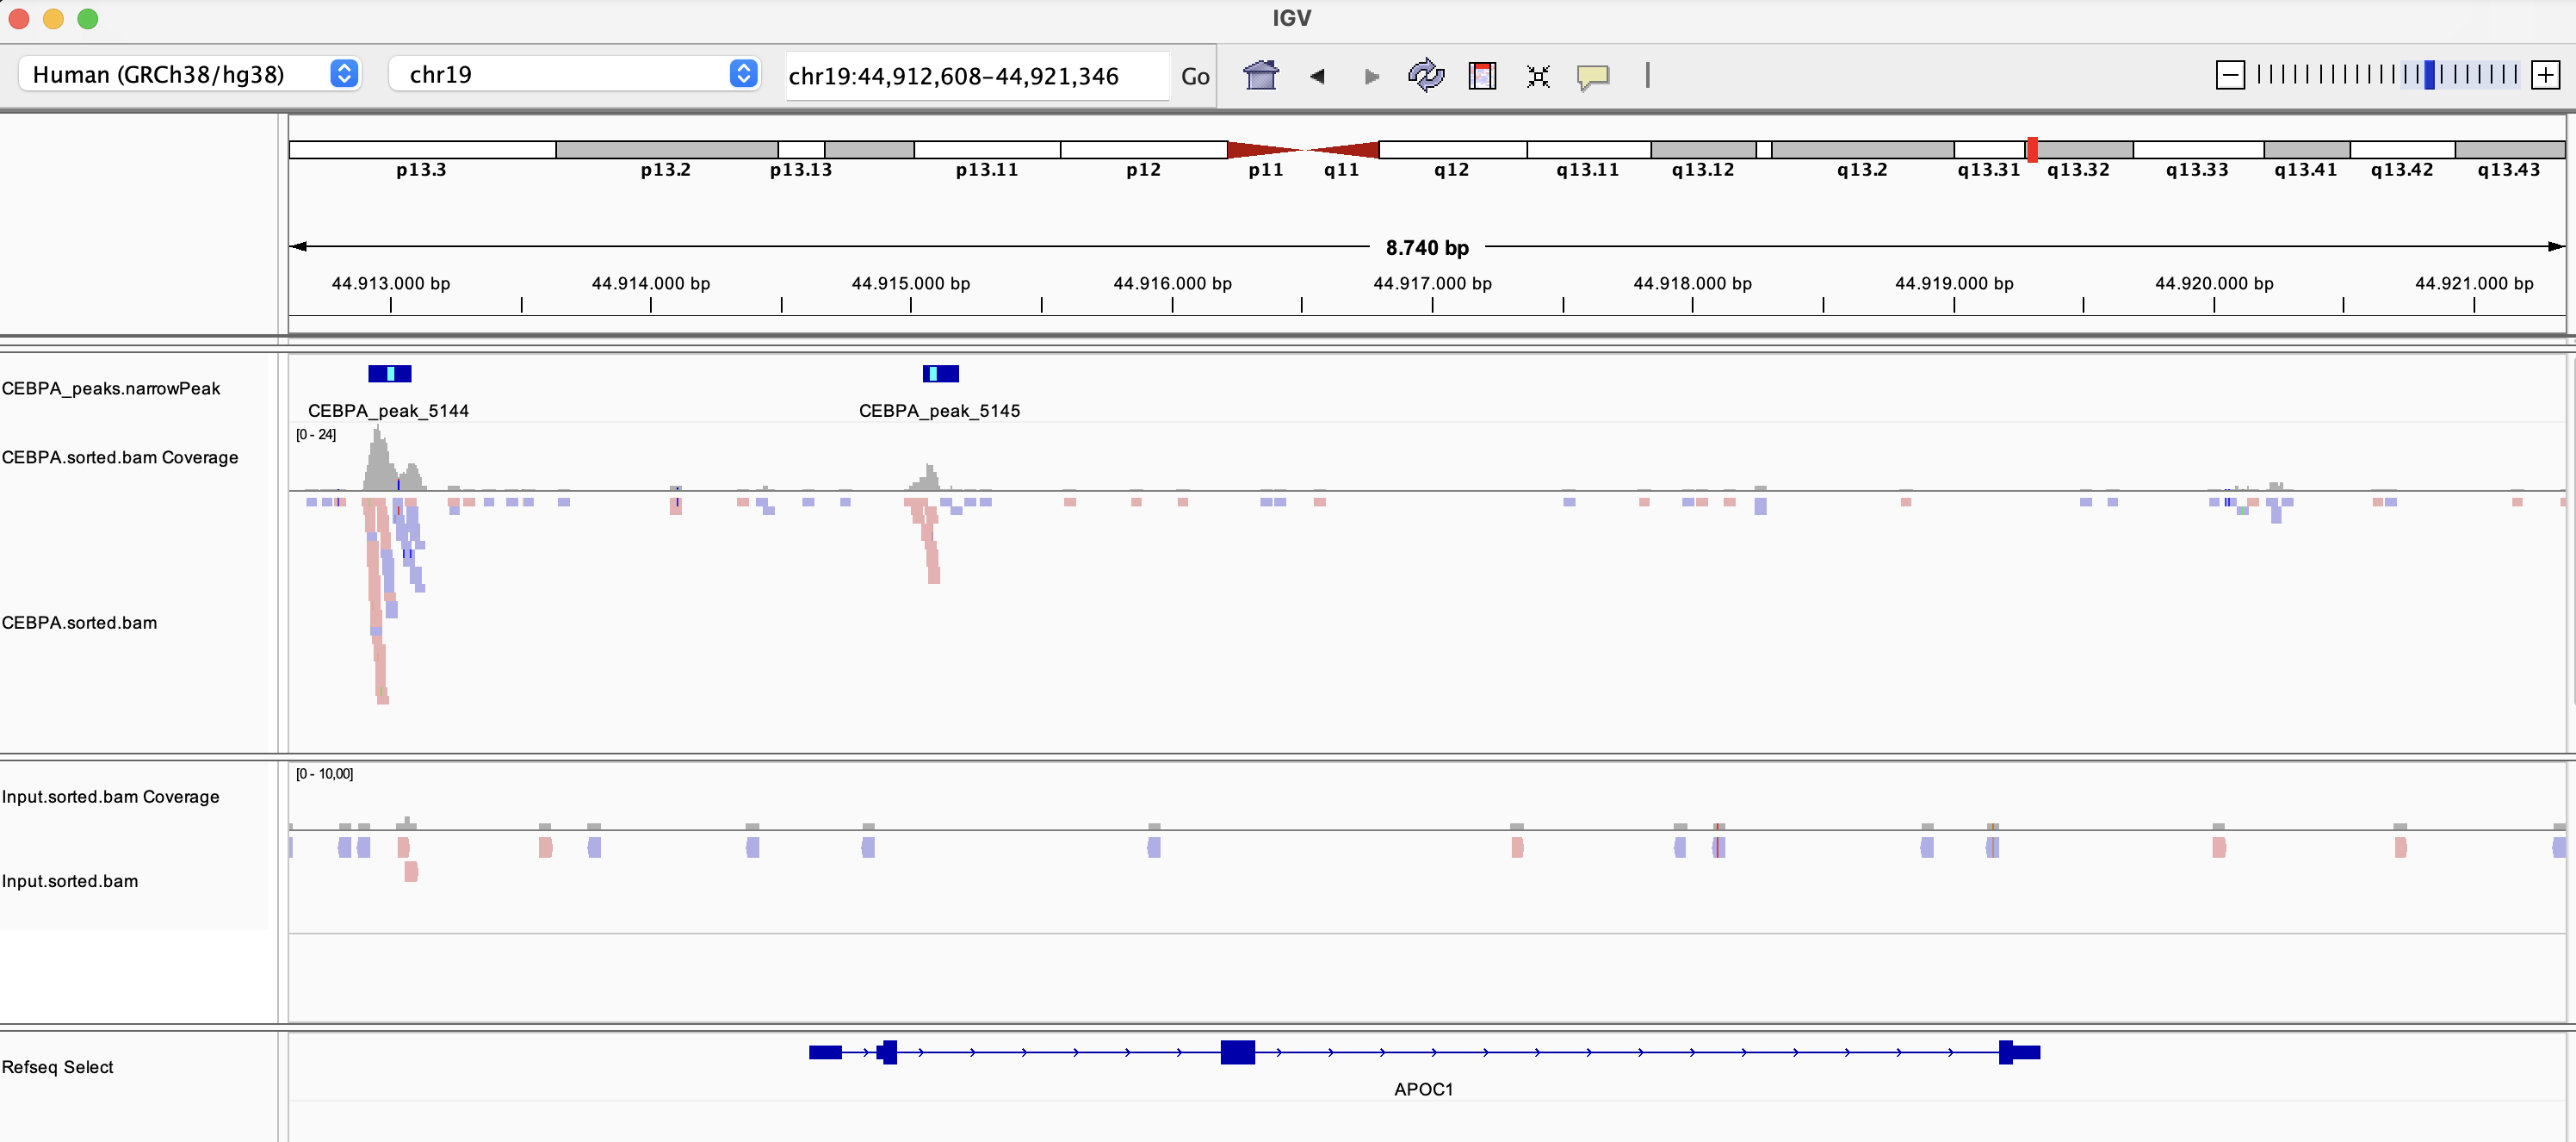

**Question**: Not all peaks are equally strong. Sort the peaks on their q-value (column 9) or fold enrichment (column 7) and look at the strongest peaks in IGV. Do you recognise the genes nearby? What do the weakest peaks look like?

In [36]:
# -k9,9gr: sort on column 9, as a (general) number, in reverse order (highest first)
sort -k9,9gr peaks/CEBPA_peaks.filtered.narrowPeak | head -n 10

chr21	44968059	44968436	CEBPA_peak_8155	1193	.	50.1298	128.859	119.368	205


chr16	4935327	4935685	CEBPA_peak_4841	1169	.	50.2669	125.355	116.978	133


chr9	19161753	19162092	CEBPA_peak_13623	1147	.	50.3576	122.677	114.777	149


chr9	134371751	134372073	CEBPA_peak_14156	1124	.	47.3531	119.984	112.452	183


chr5	172775504	172775831	CEBPA_peak_10986	1109	.	48.056	118.433	110.966	139


chr1	1764275	1764532	CEBPA_peak_7	1099	.	47.3791	117.282	109.914	119


chr11	35927794	35928102	CEBPA_peak_2225	1096	.	48.3097	117.033	109.685	176


chr2	237966671	237966960	CEBPA_peak_7653	992	.	44.1871	106.194	99.2957	134


chr14	99480941	99481302	CEBPA_peak_4352	990	.	43.9072	105.93	99.046	135


chr3	196055734	196056186	CEBPA_peak_9460	990	.	43.9072	105.93	99.046	248


## Step 8: biological interpretation

We now have ~ 14,500 CEBPA binding sites. Let's try to answer our research questions.

### 8.1 Signal around the peaks

deepTools can visualize ChIP-seq signal around a set of regions. With `computeMatrix` we extract the signal of the bigWig files in a window of 2 kb around the summit of each peak, `plotHeatmap` draws a heatmap (one row per peak, sorted on signal strength) together with the average profile on top. See the [deepTools gallery](https://deeptools.readthedocs.io/en/latest/content/example_gallery.html) for more examples.

First, we make a BED file with the summit of each (filtered) peak: start + column 10.

In [37]:
awk 'BEGIN {OFS = "\t"} {summit = $2 + $10; print $1, summit, summit + 1, $4, $9}' peaks/CEBPA_peaks.filtered.narrowPeak \
    > peaks/CEBPA_summits.filtered.bed
head -n 3 peaks/CEBPA_summits.filtered.bed

chr1	1281941	1281942	CEBPA_peak_2	1.52578


chr1	1308230	1308231	CEBPA_peak_3	27.7882


chr1	1398343	1398344	CEBPA_peak_4	5.97731


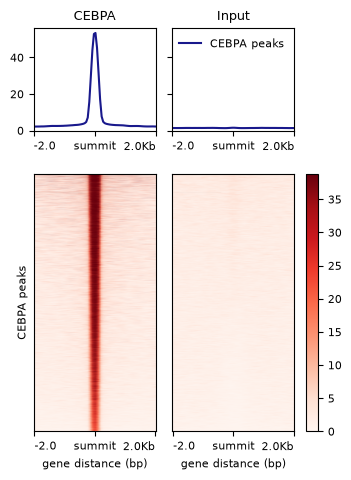

In [38]:
mkdir -p heatmaps
computeMatrix reference-point \
    -S bigwig/CEBPA.bw bigwig/Input.bw \
    -R peaks/CEBPA_summits.filtered.bed \
    --referencePoint center \
    -b 2000 -a 2000 \
    --binSize 50 \
    -p 8 \
    -o heatmaps/CEBPA_peaks.mat.gz
plotHeatmap \
    -m heatmaps/CEBPA_peaks.mat.gz \
    -o heatmaps/CEBPA_peaks.png \
    --samplesLabel CEBPA Input \
    --regionsLabel "CEBPA peaks" \
    --refPointLabel summit \
    --colorMap Reds \
    --heatmapHeight 10 \
    --dpi 100
display < heatmaps/CEBPA_peaks.png

**Question**: What do you notice about the shape and width of the signal? And about the Input? Is there a difference in peak height among the peaks?

### 8.2 Where are the peaks located relative to genes?

To annotate the peaks we use [HOMER](http://homer.ucsd.edu/homer/) (Hypergeometric Optimization of Motif EnRichment), a suite of tools for motif discovery and ChIP-seq analysis. `annotatePeaks.pl` assigns each peak to the closest transcription start site (TSS) and determines whether it is located in a promoter (-1 kb to +100 bp of a TSS), exon, intron, transcription termination site (TTS) or intergenic region. It uses the gene annotation of the HOMER hg38 package (RefSeq).

HOMER expects a peak file with a unique peak ID in column 4 and the strand in column 6, the narrowPeak file has both. Using `-size 200` we annotate a region of 200 bp centred on the peak instead of the full peak (this takes ~ 2 minutes).

In [39]:
# -annStats: write statistics on the genomic annotation to a file
# 2> /dev/null: hide the progress messages
annotatePeaks.pl peaks/CEBPA_peaks.filtered.narrowPeak hg38 \
    -size 200 \
    -annStats annotation/CEBPA_annStats.txt \
    > annotation/CEBPA_peaks.annotated.txt 2> /dev/null
head -n 3 annotation/CEBPA_peaks.annotated.txt | cut -f 1-4,8,10,16

PeakID (cmd=annotatePeaks.pl peaks/CEBPA_peaks.filtered.narrowPeak hg38 -size 200 -annStats annotation/CEBPA_annStats.txt)	Chr	Start	End	Annotation	Distance to TSS	Gene Name


CEBPA_peak_8155	chr21	44968148	44968348	intron (NM_001316986, intron 4 of 4)	25838	LINC00163


CEBPA_peak_4841	chr16	4935406	4935606	intron (NM_002705, intron 1 of 21)	1642	PPL


The most important columns of the output are the genomic annotation (column 8), the distance to the closest TSS (column 10) and the gene name of the closest TSS (column 16). The statistics file summarises the annotation (column 2: number of peaks, column 4: log2 enrichment compared to what you would expect by chance, given the size of each type of region in the genome):

In [40]:
head -n 12 annotation/CEBPA_annStats.txt | cut -f 1,2,4 | column -t -s $'\t'

Annotation  Number of peaks  Log2 Ratio (obs/exp)


3UTR        184.0            0.530


miRNA       0.0              -0.598


ncRNA       56.0             0.735


TTS         205.0            0.422


...

Intron      7207.0           0.281


Intergenic  5109.0           -0.620


Promoter    1438.0           3.077


5UTR        39.0             1.635


snoRNA      0.0              -0.002


Let's also make a histogram of the distance between the peaks and the closest TSS (in bins of 10 kb, up to 100 kb):

In [41]:
tail -n +2 annotation/CEBPA_peaks.annotated.txt \
    | awk -F '\t' '{d = ($10 < 0) ? -$10 : $10; bin = int(d / 10000); if (bin > 10) bin = 10; n[bin]++}
                   END {for (b = 0; b <= 10; b++) {label = (b < 10) ? b * 10 "-" (b + 1) * 10 " kb" : "> 100 kb";
                        bar = ""; for (i = 0; i < n[b] / 50; i++) bar = bar "#"; printf "%-12s %6d %s\n", label, n[b], bar}}'

0-10 kb        4981 ####################################################################################################


10-20 kb       2061 ##########################################


20-30 kb       1467 ##############################


30-40 kb       1098 ######################


40-50 kb        769 ################


...

60-70 kb        466 ##########


70-80 kb        420 #########


80-90 kb        334 #######


90-100 kb       256 ######


> 100 kb       2008 #########################################


**Question**: Does CEBPA bind mainly to promoters or to distal regions? What does this tell you about how CEBPA regulates genes?

### 8.3 Which genes are close to the strongest peaks?

Let's look at the closest gene of the 30 strongest peaks (highest q-value, column 9 of the narrowPeak file). The peak ID is in column 1 of the annotation file, so we first sort the narrowPeak file, take the peak names and look up their annotation.

In [42]:
sort -k9,9gr peaks/CEBPA_peaks.filtered.narrowPeak | head -n 30 | cut -f 4 > annotation/CEBPA_top30.txt
# awk with two files: first read the top 30 peak names (NR == FNR), then print the annotation of these peaks
awk -F '\t' 'NR == FNR {top[$1] = 1; next} ($1 in top) {print $1"\t"$8"\t"$10"\t"$16}' annotation/CEBPA_top30.txt annotation/CEBPA_peaks.annotated.txt \
    | sed 's/ (.*)//' \
    | sort -k4,4 \
    | column -t -s $'\t'

CEBPA_peak_2404   3' UTR        2649     MYEOV


CEBPA_peak_12056  Intergenic    -199033  AHR


CEBPA_peak_11700  Intergenic    -2279    CENPW


CEBPA_peak_257    Intergenic    -3792    CSF3R


CEBPA_peak_6540   Intergenic    -109945  CYRIA


...

CEBPA_peak_372    intron        41162    SSBP3


CEBPA_peak_9726   Intergenic    46825    SULT1B1


CEBPA_peak_9460   intron        26130    TFRC


CEBPA_peak_2032   intron        3486     TOLLIP


CEBPA_peak_7653   promoter-TSS  -129     UBE2F


The strongest peaks are not always close to the "textbook" liver genes. Keep in mind that the closest gene is not necessarily the gene that is regulated, and that liver tissue does not only contain hepatocytes: CSF3R, for example, is a myeloid gene (the liver contains macrophages, the Kupffer cells, and neutrophils).

Another way to look at the data is to count the number of peaks close to each gene (within 50 kb of its TSS). Genes that are controlled by many enhancers are often important for the identity of the cell.

In [43]:
# column 10: distance to TSS, column 16: gene name; skip peaks without a gene name
tail -n +2 annotation/CEBPA_peaks.annotated.txt \
    | awk -F '\t' '{d = ($10 < 0) ? -$10 : $10; if (d < 50000 && $16 != "") print $16}' \
    | sort | uniq -c | sort -k1,1nr | head -n 20

     11 PTP4A1


      9 GHR


      9 LOC101928119


      9 SCARB1


      8 ACACB


...

      7 CALM2


      7 CYB5A


      7 DLG2


      7 EPAS1


      7 FOXO3


And let's check a few classic liver genes: ALB (albumin), APOA1, APOB and APOC1 (apolipoproteins), CYP2E1, SERPINA1 (alpha-1-antitrypsin), TTR (transthyretin), TF (transferrin), HP (haptoglobin) and FGB (fibrinogen).

In [44]:
for gene in ALB APOA1 APOB APOC1 CYP2E1 SERPINA1 TTR TF HP FGB
do
    echo -e "${gene}\t$(tail -n +2 annotation/CEBPA_peaks.annotated.txt | awk -F '\t' -v g=${gene} '$16 == g' | wc -l) peaks"
done

ALB	4 peaks


APOA1	1 peaks


APOB	6 peaks


APOC1	1 peaks


CYP2E1	2 peaks


SERPINA1	4 peaks


TTR	1 peaks


TF	3 peaks


HP	4 peaks


FGB	4 peaks


**Question**: Look up a few of these genes in [GeneCards](https://www.genecards.org/) or the [Human Protein Atlas](https://www.proteinatlas.org/). Are they liver genes? Which functions do they have?

### 8.4 Motif analysis: which DNA sequence does CEBPA recognise?

If the peaks are real CEBPA binding sites, we expect to find the CEBPA motif close to the summit of the peaks. HOMER's `findMotifsGenome.pl` does two things:

1. **Known motif enrichment**: for each motif in the HOMER database (~ 450 motifs of known TFs) it counts how many peaks contain the motif, compared to a set of *background* regions with the same GC content selected randomly from the genome.
2. ***De novo* motif discovery**: it searches for short sequences (here of length 8, 10 and 12 bp) that are enriched in the peaks compared to the background, without using prior knowledge. The discovered motifs are then compared to the database of known motifs.

We use the 500 strongest peaks and a region of 100 bp around the summit (`-size 100`): the binding site should be close to the summit, and smaller regions give a better signal to noise ratio. This takes ~ 5 minutes.

In [45]:
sort -k5,5gr peaks/CEBPA_summits.filtered.bed | head -n 500 > peaks/CEBPA_top500_summits.bed
# -size 100: use 100 bp around the summit, -len 8,10,12: length of the de novo motifs
# -p 8: use 8 threads, -nomotif would skip de novo motif discovery
findMotifsGenome.pl peaks/CEBPA_top500_summits.bed hg38 motifs/CEBPA_top500 \
    -size 100 \
    -len 8,10,12 \
    -p 8 > motifs.CEBPA.log 2>&1
ls motifs/CEBPA_top500

homerMotifs.all.motifs  homerResults       knownResults.txt


homerMotifs.motifs10    homerResults.html  motifFindingParameters.txt


homerMotifs.motifs12    knownResults       nonRedundant.motifs


homerMotifs.motifs8     knownResults.html  seq.autonorm.tsv


The results are summarised in two html files (`knownResults.html` and `homerResults.html`) that you can open in a browser. The known motif results are also stored in a text file. Let's look at the 15 most enriched known motifs:

In [46]:
# columns: motif name, consensus, p-value, % of target (peak) sequences with the motif, % of background sequences with the motif
head -n 16 motifs/CEBPA_top500/knownResults.txt | cut -f 1,2,3,7,9 | sed 's/\/Homer//' | column -t -s $'\t'

Motif Name                                         Consensus         P-value  % of Target Sequences with Motif  % of Background Sequences with Motif


CEBP(bZIP)/ThioMac-CEBPb-ChIP-Seq(GSE21512)        ATTGCGCAAC        1e-322   69.60%                            5.06%


NFIL3(bZIP)/HepG2-NFIL3-ChIP-Seq(Encode)           VTTACGTAAYNNNNN   1e-277   55.40%                            2.99%


HLF(bZIP)/HSC-HLF.Flag-ChIP-Seq(GSE69817)          RTTATGYAAB        1e-256   58.20%                            4.26%


CEBP:AP1(bZIP)/ThioMac-CEBPb-ChIP-Seq(GSE21512)    DRTGTTGCAA        1e-144   42.80%                            4.61%


...

Foxa2(Forkhead)/Liver-Foxa2-ChIP-Seq(GSE25694)     CYTGTTTACWYW      1e-4     7.60%                             3.59%


FOXA1(Forkhead)/MCF7-FOXA1-ChIP-Seq(GSE26831)      WAAGTAAACA        1e-4     9.00%                             4.59%


Tlx?(NR)/NPC-H3K4me1-ChIP-Seq(GSE16256)            CTGGCAGSCTGCCA    1e-4     5.00%                             1.96%


FOXA1(Forkhead)/LNCAP-FOXA1-ChIP-Seq(GSE27824)     WAAGTAAACA        1e-4     10.60%                            5.88%


Lhx6/Neurons-Lhx6-ChIP-seq(GSE85704)               YCCTRATTAG        1e-4     11.80%                            6.90%


And the top *de novo* motifs, with the best matching known motif. The logos are stored as SVG images, we put them in a small html page to show them in this notebook.

In [47]:
{
    echo "<table>"
    for i in 1 2 3 4 5
    do
        motif_file=motifs/CEBPA_top500/homerResults/motif${i}.motif
        [ -f ${motif_file} ] || continue
        # header line of the motif file: >consensus  best match  log odds threshold  log p-value  0  T:...,B:...,P:...
        best_match=$(head -n 1 ${motif_file} | cut -f 2 | sed 's/.*BestGuess://')
        stats=$(head -n 1 ${motif_file} | cut -f 6 | sed 's/,/ /g')
        echo "<tr><td>motif ${i}</td><td>$(cat motifs/CEBPA_top500/homerResults/motif${i}.logo.svg)</td><td>${best_match}<br>${stats}</td></tr>"
    done
    echo "</table>"
} > motifs/CEBPA_top500/de_novo_motifs.html
displayHTML < motifs/CEBPA_top500/de_novo_motifs.html

motif 1,CEBPG/MA0838.1/Jaspar(0.946)T:412.0(82.40%) B:3012.2(3.49%) P:1e-501
motif 2,CEBP:AP1(bZIP)/ThioMac-CEBPb-ChIP-Seq(GSE21512)/Homer(0.853)T:112.0(22.40%) B:1593.6(1.85%) P:1e-83
motif 3,ATF4/MA0833.3/Jaspar(0.867)T:53.0(10.60%) B:1101.4(1.28%) P:1e-30
motif 4,AP-2alpha(AP2)/Hela-AP2alpha-ChIP-Seq(GSE31477)/Homer(0.878)T:19.0(3.80%) B:293.0(0.34%) P:1e-13
motif 5,Dmrt1/MA1603.2/Jaspar(0.617)T:10.0(2.00%) B:47.0(0.05%) P:1e-12


**Question**: Is the CEBP motif the most enriched motif? In what fraction of the peaks is it present? Which other motifs are enriched, and do you know these TFs? (Hint: think about the other TFs that were studied in the paper, and about *co-binding* of TFs at liver enhancers.)

**Question**: Why do we compare to background sequences with the same GC content, and not to the genome as a whole?

### 8.5 Gene ontology enrichment

Which biological processes are regulated by CEBPA? HOMER can perform a gene ontology (GO) enrichment analysis of the genes closest to the peaks (`-go`): it tests whether genes annotated with a certain GO term are over-represented among the genes close to a peak, compared to all genes (hypergeometric test). This takes ~ 1 minute.

We use the 2000 strongest peaks.

In [48]:
sort -k9,9gr peaks/CEBPA_peaks.filtered.narrowPeak | head -n 2000 > peaks/CEBPA_top2000.narrowPeak
annotatePeaks.pl peaks/CEBPA_top2000.narrowPeak hg38 -size 200 -go go/CEBPA_top2000 > /dev/null 2> /dev/null
ls go/CEBPA_top2000 | head

biocyc.txt


biological_process.txt


cellular_component.txt


chromosome.txt


cosmic.txt


gene3d.txt


geneOntology.html


gwas.txt


interactions.txt


interpro.txt


In [49]:
# columns: term, natural log of the p-value, number of genes in the term, number of target genes (genes close to a peak) in the term, fraction of the target genes in the term
head -n 16 go/CEBPA_top2000/biological_process.txt | cut -f 2,4,5,6,7 | column -t -s $'\t' | cut -c 1-150

Term                                      logP               Genes in Term  Target Genes in Term  Fraction of Targets in Term


organic acid metabolic process            -50.7493258711474  824            134                   0.106858054226475


oxoacid metabolic process                 -49.3804743947179  817            132                   0.105263157894737


small molecule metabolic process          -48.8066051390526  1631           210                   0.167464114832536


carboxylic acid metabolic process         -44.4991655034678  794            125                   0.0996810207336523


...

small molecule biosynthetic process       -29.2650181156092  465            76                    0.0606060606060606


lipid metabolic process                   -28.8271853635003  1223           148                   0.118022328548644


response to oxygen-containing compound    -28.7762906453952  1557           177                   0.141148325358852


cellular response to chemical stimulus    -27.5152802319123  2420           246                   0.196172248803828


positive regulation of metabolic process  -27.1716397511792  3815           353                   0.281499202551834


**Question**: Are these processes in line with the function of the liver?

**Question**: Assigning each peak to the closest gene is a simplification. Can you think of cases where this goes wrong? (Hint: enhancers can regulate genes that are hundreds of kb away, and skip genes in between.) The [GREAT](http://great.stanford.edu/) web tool uses a more sophisticated way to link regions to genes. Upload the peaks (BED file, first three columns) to GREAT and compare the results.

### 8.6 Are CEBPA bound regions active enhancers? Histone ChIP-seq of H3K27ac

A TF binding site is not necessarily an *active* regulatory region. Active enhancers and promoters are marked by **acetylation of lysine 27 of histone H3 (H3K27ac)**, which can be mapped by ChIP-seq with an antibody against this modification. Unlike a TF, a histone mark covers broader regions (nucleosomes on both sides of the TF binding site, often 1 - 5 kb).

We use H3K27ac ChIP-seq data of the [ENTEx](https://www.encodeproject.org/search/?type=Experiment&internal_tags=ENTEx) project (ENCODE): tissues from four human donors, profiled with the same protocols. We compare the **liver** with the **spleen** of the same donor (ENCDO575WHY, female, 41 years), so differences cannot be due to genetic differences between donors. The spleen is an immune organ, and contains many myeloid cells (in which CEBPA is also active), but no hepatocytes.

| Sample | ENCODE experiment | Filtered alignments (GRCh38) |
|---|---|---|
| Liver H3K27ac | ENCSR864OOO | ENCFF478KET |
| Liver Input | ENCSR309LQG | ENCFF897PIQ |
| Spleen H3K27ac | ENCSR343DFX | ENCFF233UJK |
| Spleen Input | ENCSR749YQP | ENCFF041GWX |

These are deeper datasets (~ 25 - 50 million reads of 76 bp), aligning them takes a few hours. We therefore download the alignments made by the ENCODE pipeline, which uses the same steps as we did above: alignment with bowtie2 to GRCh38, removal of reads with low mapping quality and removal of duplicates.

Note that the CEBPA ChIP-seq and the H3K27ac ChIP-seq come from different persons. Most enhancers are shared between individuals, so this is not a big problem.

Downloading the four files (~ 12 GB) takes ~ 5 - 10 minutes. ENCODE also gives the *md5 checksum* of each file: a short "fingerprint" of its content. If the checksum of the downloaded file is the same, we know that the download is complete and not corrupted (`md5sum -c`).

In [4]:
mkdir -p alignment_h3k27ac
# ENCODE file accession, our sample name and md5 checksum of the file (separated by spaces)
cat > alignment_h3k27ac/files.tsv << EOF
ENCFF478KET Liver_H3K27ac  c500c78e468bae180de89ae49baa4966
ENCFF897PIQ Liver_Input    09d668752c6493676800a5066978435d
ENCFF233UJK Spleen_H3K27ac 1ca3897e3c75ce09f0b8d9f64fe014ca
ENCFF041GWX Spleen_Input   20cd0d7e91b97849f530d7f0cb46e93d
EOF
while read ACC NAME MD5
do
    echo "Downloading ${ACC} (${NAME})"
    curl -fsSL --retry 3 -o alignment_h3k27ac/${NAME}.bam https://www.encodeproject.org/files/${ACC}/@@download/${ACC}.bam
done < alignment_h3k27ac/files.tsv
# md5sum -c reads lines of the form "<checksum>  <file>" and checks each file
awk '{print $3"  alignment_h3k27ac/"$2".bam"}' alignment_h3k27ac/files.tsv | md5sum -c
ls -lhgG alignment_h3k27ac

alignment_h3k27ac/Liver_H3K27ac.bam: OK


alignment_h3k27ac/Liver_Input.bam: OK


alignment_h3k27ac/Spleen_H3K27ac.bam: OK


alignment_h3k27ac/Spleen_Input.bam: OK


total 11G


-rw-rw----+ 1 2.1G Oct 28 19:47 Liver_H3K27ac.bam


-rw-rw----+ 1 3.3G Oct 28 19:50 Liver_Input.bam


-rw-rw----+ 1 2.0G Oct 28 19:52 Spleen_H3K27ac.bam


-rw-rw----+ 1 3.8G Oct 28 19:55 Spleen_Input.bam


-rw-rw----+ 1  240 Oct 28 19:46 files.tsv


The BAM files of ENCODE are sorted, but not indexed. Let's index them and count the reads (~ 30 seconds).

In [5]:
for sample in Liver_H3K27ac Liver_Input Spleen_H3K27ac Spleen_Input
do
    samtools index -@ 8 -o alignment_h3k27ac/${sample}.bam.bai alignment_h3k27ac/${sample}.bam
    echo -e "${sample}\t$(samtools idxstats alignment_h3k27ac/${sample}.bam | awk '{s += $3} END {print s}') reads"
done

Liver_H3K27ac	42287914 reads


Liver_Input	66922421 reads


Spleen_H3K27ac	37389936 reads


Spleen_Input	78392579 reads


We make bigWig files of the two H3K27ac samples, just like in Step 6 (~ 1 minute per sample).

In [6]:
for sample in Liver_H3K27ac Spleen_H3K27ac
do
    bamCoverage \
        -b alignment_h3k27ac/${sample}.bam \
        -o bigwig/${sample}.bw \
        --binSize 50 \
        --extendReads 200 \
        --normalizeUsing RPGC \
        --effectiveGenomeSize 2701495761 \
        -p 8 2> /dev/null
done
ls -lhgG bigwig

total 403M


-rw-rw----+ 1  36M Oct 28 19:37 CEBPA.bw


-rw-rw----+ 1  30M Oct 28 19:37 Input.bw


-rw-rw----+ 1 178M Oct 28 19:57 Liver_H3K27ac.bw


-rw-rw----+ 1 166M Oct 28 19:58 Spleen_H3K27ac.bw


Now we plot the H3K27ac signal of liver and spleen around the summits of the CEBPA peaks, in a larger window (5 kb on each side) because histone marks are broader. The peaks are sorted on the H3K27ac signal in the liver (`--sortUsingSamples 2`) and divided into 3 groups using *k-means clustering* on the two H3K27ac samples (`--kmeans 3 --clusterUsingSamples 2 3`), to find groups of peaks with a similar H3K27ac pattern.

*Warning* For clustering nan values have to be replaced by zeros 


Samples used for ordering within each group:  [1]


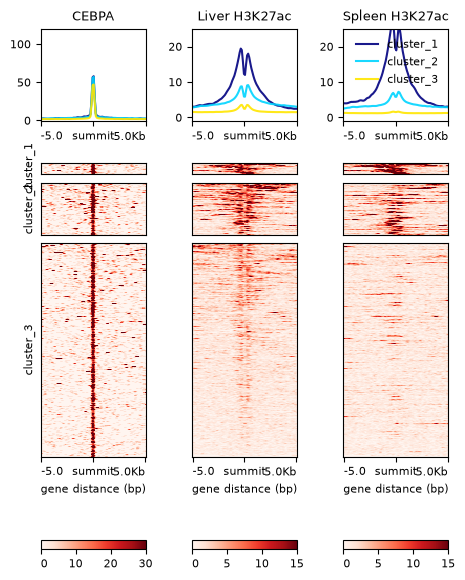

In [7]:
computeMatrix reference-point \
    -S bigwig/CEBPA.bw bigwig/Liver_H3K27ac.bw bigwig/Spleen_H3K27ac.bw \
    -R peaks/CEBPA_summits.filtered.bed \
    --referencePoint center \
    -b 5000 -a 5000 \
    --binSize 100 \
    -p 8 \
    -o heatmaps/CEBPA_peaks_H3K27ac.mat.gz
plotHeatmap \
    -m heatmaps/CEBPA_peaks_H3K27ac.mat.gz \
    -o heatmaps/CEBPA_peaks_H3K27ac.png \
    --samplesLabel CEBPA "Liver H3K27ac" "Spleen H3K27ac" \
    --refPointLabel summit \
    --kmeans 3 \
    --clusterUsingSamples 2 3 \
    --sortUsingSamples 2 \
    --colorMap Reds \
    --zMax 30 15 15 \
    --yMax 120 25 25 \
    --heatmapHeight 12 \
    --outFileSortedRegions heatmaps/CEBPA_peaks_H3K27ac.clusters.bed \
    --dpi 100
display < heatmaps/CEBPA_peaks_H3K27ac.png

In [8]:
# number of peaks in each cluster (last column of the file)
cut -f 13 heatmaps/CEBPA_peaks_H3K27ac.clusters.bed | sort | uniq -c

    623 cluster_1


   2708 cluster_2


  11137 cluster_3


      1 deepTools_group


**Question**: Describe the 3 clusters. Are most CEBPA peaks marked by H3K27ac in the liver? And in the spleen? Notice the *dip* in the H3K27ac signal exactly at the CEBPA summit. Can you explain this? (Hint: H3K27ac is a modification of a histone. Where are the nucleosomes when a TF is bound?)

### 8.7 Differential H3K27ac: liver versus spleen

Which regions are significantly more acetylated in the liver than in the spleen, and vice versa? MACS3 has a simple method to compare two conditions, `bdgdiff` (see the [MACS documentation](https://macs3-project.github.io/MACS/docs/bdgdiff.html)). It needs, for each sample, the ChIP pileup and the local background (lambda) as *bedGraph* files, which `macs3 callpeak` writes when we add `-B`.

For histone marks there is no clear bimodal pattern of forward and reverse reads (see the figure of Step 7, panel B), so the fragment length model can fail. We therefore switch the model off (`--nomodel`) and extend all reads to a fixed length (`--extsize`). To find a good value, we first predict the fragment length for each sample with `macs3 predictd` (a few seconds).

In [9]:
for sample in Liver_H3K27ac Spleen_H3K27ac
do
    echo -e "${sample}\t$(macs3 predictd -i alignment_h3k27ac/${sample}.bam -g hs 2>&1 | grep "predicted fragment length" | sed 's/.*predicted fragment length is //')"
done

Liver_H3K27ac	226 bps 


Spleen_H3K27ac	209 bps 


We will use `--extsize 200` for both samples, so the reads are extended in the same way. `--broad` calls broad peaks (regions of enrichment) in addition to the narrow peaks, which is more suitable for histone marks. This takes ~ 2 minutes per sample.

In [10]:
mkdir -p peaks_h3k27ac
for tissue in Liver Spleen
do
    # -B: write bedGraph files of the pileup and the local lambda
    # --SPMR: don't use this together with bdgdiff, the pileup must be in raw read counts
    macs3 callpeak \
        -t alignment_h3k27ac/${tissue}_H3K27ac.bam \
        -c alignment_h3k27ac/${tissue}_Input.bam \
        -f BAM \
        -g hs \
        -n ${tissue}_H3K27ac \
        --outdir peaks_h3k27ac \
        --nomodel --extsize 200 \
        --broad \
        -B 2> peaks_h3k27ac/${tissue}_H3K27ac.log
    echo -e "${tissue}\t$(wc -l < peaks_h3k27ac/${tissue}_H3K27ac_peaks.broadPeak) broad peaks"
done
ls -lhgG peaks_h3k27ac

Liver	58450 broad peaks


Spleen	68215 broad peaks


total 14G


-rw-rw----+ 1  11K Oct 28 20:00 Liver_H3K27ac.log


-rw-rw----+ 1 4.1G Oct 28 20:00 Liver_H3K27ac_control_lambda.bdg


...

-rw-rw----+ 1 4.7G Oct 28 20:01 Spleen_H3K27ac_control_lambda.bdg


-rw-rw----+ 1 5.2M Oct 28 20:01 Spleen_H3K27ac_peaks.broadPeak


-rw-rw----+ 1 6.8M Oct 28 20:01 Spleen_H3K27ac_peaks.gappedPeak


-rw-rw----+ 1 5.5M Oct 28 20:01 Spleen_H3K27ac_peaks.xls


-rw-rw----+ 1 2.2G Oct 28 20:01 Spleen_H3K27ac_treat_pileup.bdg


`bdgdiff` needs the *sequencing depth* of each sample (the number of reads used by MACS). MACS scales the treatment and control to the same depth (by default the larger one is scaled down to the smaller one). Here the Inputs are deeper than the ChIPs, so the depth of the ChIP is used. It is printed in the xls file.

In [11]:
grep -E "tags after filtering in (treatment|control)" peaks_h3k27ac/Liver_H3K27ac_peaks.xls peaks_h3k27ac/Spleen_H3K27ac_peaks.xls

peaks_h3k27ac/Liver_H3K27ac_peaks.xls:# tags after filtering in treatment: 42287896


peaks_h3k27ac/Liver_H3K27ac_peaks.xls:# tags after filtering in control: 66922405


peaks_h3k27ac/Spleen_H3K27ac_peaks.xls:# tags after filtering in treatment: 37389914


peaks_h3k27ac/Spleen_H3K27ac_peaks.xls:# tags after filtering in control: 78392562


In [12]:
# bdgdiff expects the depth in million reads
DEPTH_LIVER=$(grep "tags after filtering in treatment" peaks_h3k27ac/Liver_H3K27ac_peaks.xls | awk '{print $NF / 1e6}')
DEPTH_SPLEEN=$(grep "tags after filtering in treatment" peaks_h3k27ac/Spleen_H3K27ac_peaks.xls | awk '{print $NF / 1e6}')
echo "liver: ${DEPTH_LIVER} million reads, spleen: ${DEPTH_SPLEEN} million reads"

liver: 42.2879 million reads, spleen: 37.3899 million reads


Now we can run `bdgdiff`. It computes, for each position, the *log likelihood ratio* (LLR) of the data being enriched in condition 1 vs condition 2 (and vice versa, and of being enriched in both). Regions with a LLR above the cutoff (`-C 3`, by default) are reported in three files: `cond1` (higher in liver), `cond2` (higher in spleen) and `common` (similar in both).

- `-g 100`: maximum gap to merge nearby differential regions
- `-l 200`: minimum length of a differential region

This takes ~ 5 minutes.

In [13]:
mkdir -p diff_h3k27ac
macs3 bdgdiff \
    --t1 peaks_h3k27ac/Liver_H3K27ac_treat_pileup.bdg \
    --c1 peaks_h3k27ac/Liver_H3K27ac_control_lambda.bdg \
    --t2 peaks_h3k27ac/Spleen_H3K27ac_treat_pileup.bdg \
    --c2 peaks_h3k27ac/Spleen_H3K27ac_control_lambda.bdg \
    --d1 ${DEPTH_LIVER} \
    --d2 ${DEPTH_SPLEEN} \
    -g 100 \
    -l 200 \
    --outdir diff_h3k27ac \
    --o-prefix liver_vs_spleen 2> diff_h3k27ac/bdgdiff.log
# the first line of each file is a track line (for the UCSC genome browser), so we don't count it
for f in diff_h3k27ac/*.bed
do
    echo -e "$(basename ${f})\t$(tail -n +2 ${f} | wc -l) regions"
done

liver_vs_spleen_c3.0_common.bed	24515 regions


liver_vs_spleen_c3.0_cond1.bed	16286 regions


liver_vs_spleen_c3.0_cond2.bed	26576 regions


In [14]:
head -n 4 diff_h3k27ac/liver_vs_spleen_c3.0_cond1.bed

track name="condition 1 (peaks)" description="unique regions in condition 1" visibility=1


chr1	1005203	1006574	liver_vs_spleen_cond1_1	11.9912


chr1	1431354	1431677	liver_vs_spleen_cond1_2	5.21022


chr1	1432364	1432747	liver_vs_spleen_cond1_3	4.56352


Columns 1-3 are the region, column 5 is the highest LLR in the region. Let's look at the regions with the highest LLR for both conditions, and annotate them with the closest gene.

In [15]:
for cond in cond1 cond2
do
    echo "== ${cond}"
    tail -n +2 diff_h3k27ac/liver_vs_spleen_c3.0_${cond}.bed | sort -k5,5gr | head -n 15 \
        | awk 'BEGIN {OFS = "\t"} {print $1, $2, $3, $4, $5, "+"}' > diff_h3k27ac/top15_${cond}.bed
    annotatePeaks.pl diff_h3k27ac/top15_${cond}.bed hg38 2> /dev/null \
        | tail -n +2 | cut -f 2,3,4,10,16 | sort -k1,1 -k2,2n | column -t
done

== cond1


chr1   145707559  145708723  -741    PDZK1


chr11  33695321   33695884   5138    C11orf91


chr12  124821378  124821837  18064   SCARB1


chr14  64118312   64118803   -23432  MIR548H1


...

chr7   1077321    1077770    -9262   GPER1


chr7   2001096    2001383    -60668  MAD1L1


chr7   130380109  130380335  -272    CPA1


chr9   37001587   37001840   32555   PAX5


chr9   131076249  131076491  -20106  AIF1L


**Question**: Do you recognise liver genes among the closest genes of the `cond1` (liver) regions? And immune genes among the `cond2` (spleen) regions?

Finally, let's combine both datasets: how many CEBPA peaks overlap a region with a higher H3K27ac signal in the liver, a higher signal in the spleen, or a similar signal in both? (`bedtools intersect -u`: report each peak once if it overlaps at least one region.)

In [16]:
total=$(wc -l < peaks/CEBPA_peaks.filtered.narrowPeak)
for cond in cond1 cond2 common
do
    n=$(bedtools intersect -u -a peaks/CEBPA_peaks.filtered.narrowPeak -b diff_h3k27ac/liver_vs_spleen_c3.0_${cond}.bed | wc -l)
    echo -e "${cond}\t${n}\t$(echo "scale=1; 100 * ${n} / ${total}" | bc) % of the CEBPA peaks"
done

cond1	1429	9.8 % of the CEBPA peaks


cond2	648	4.4 % of the CEBPA peaks


common	1466	10.1 % of the CEBPA peaks


About 10% of the CEBPA peaks overlap a region with a higher H3K27ac signal in the liver, more than twice as many as the peaks that overlap a region with a higher signal in the spleen. Note that most CEBPA peaks don't overlap any of these regions: `bdgdiff` only reports regions with a strong signal (log likelihood ratio > 3) in at least one of the two tissues.

**Question**: What fraction of the CEBPA peaks is more active in the liver than in the spleen? What do you expect for the CEBPA peaks near the CSF3R gene (a myeloid gene, see Step 7)? Check this in IGV by loading the bigWig files of the H3K27ac samples (`bigwig/Liver_H3K27ac.bw` and `bigwig/Spleen_H3K27ac.bw`) and the differential regions (`diff_h3k27ac/*.bed`).

**Question**: Run the motif analysis of 8.4 on the CEBPA peaks that overlap a liver-specific H3K27ac region (`cond1`) and on the CEBPA peaks that overlap a spleen-specific region (`cond2`). Which other TF motifs do you find? What does this tell you about the partners of CEBPA in both tissues?

**Note**: `bdgdiff` compares a single sample per condition and therefore cannot estimate the biological variability between replicates. For a real differential analysis you should use biological replicates and a statistical method based on read counts, e.g. [DiffBind](https://bioconductor.org/packages/release/bioc/html/DiffBind.html) (which uses DESeq2 or edgeR, see the RNA-seq practical).

SCARB1

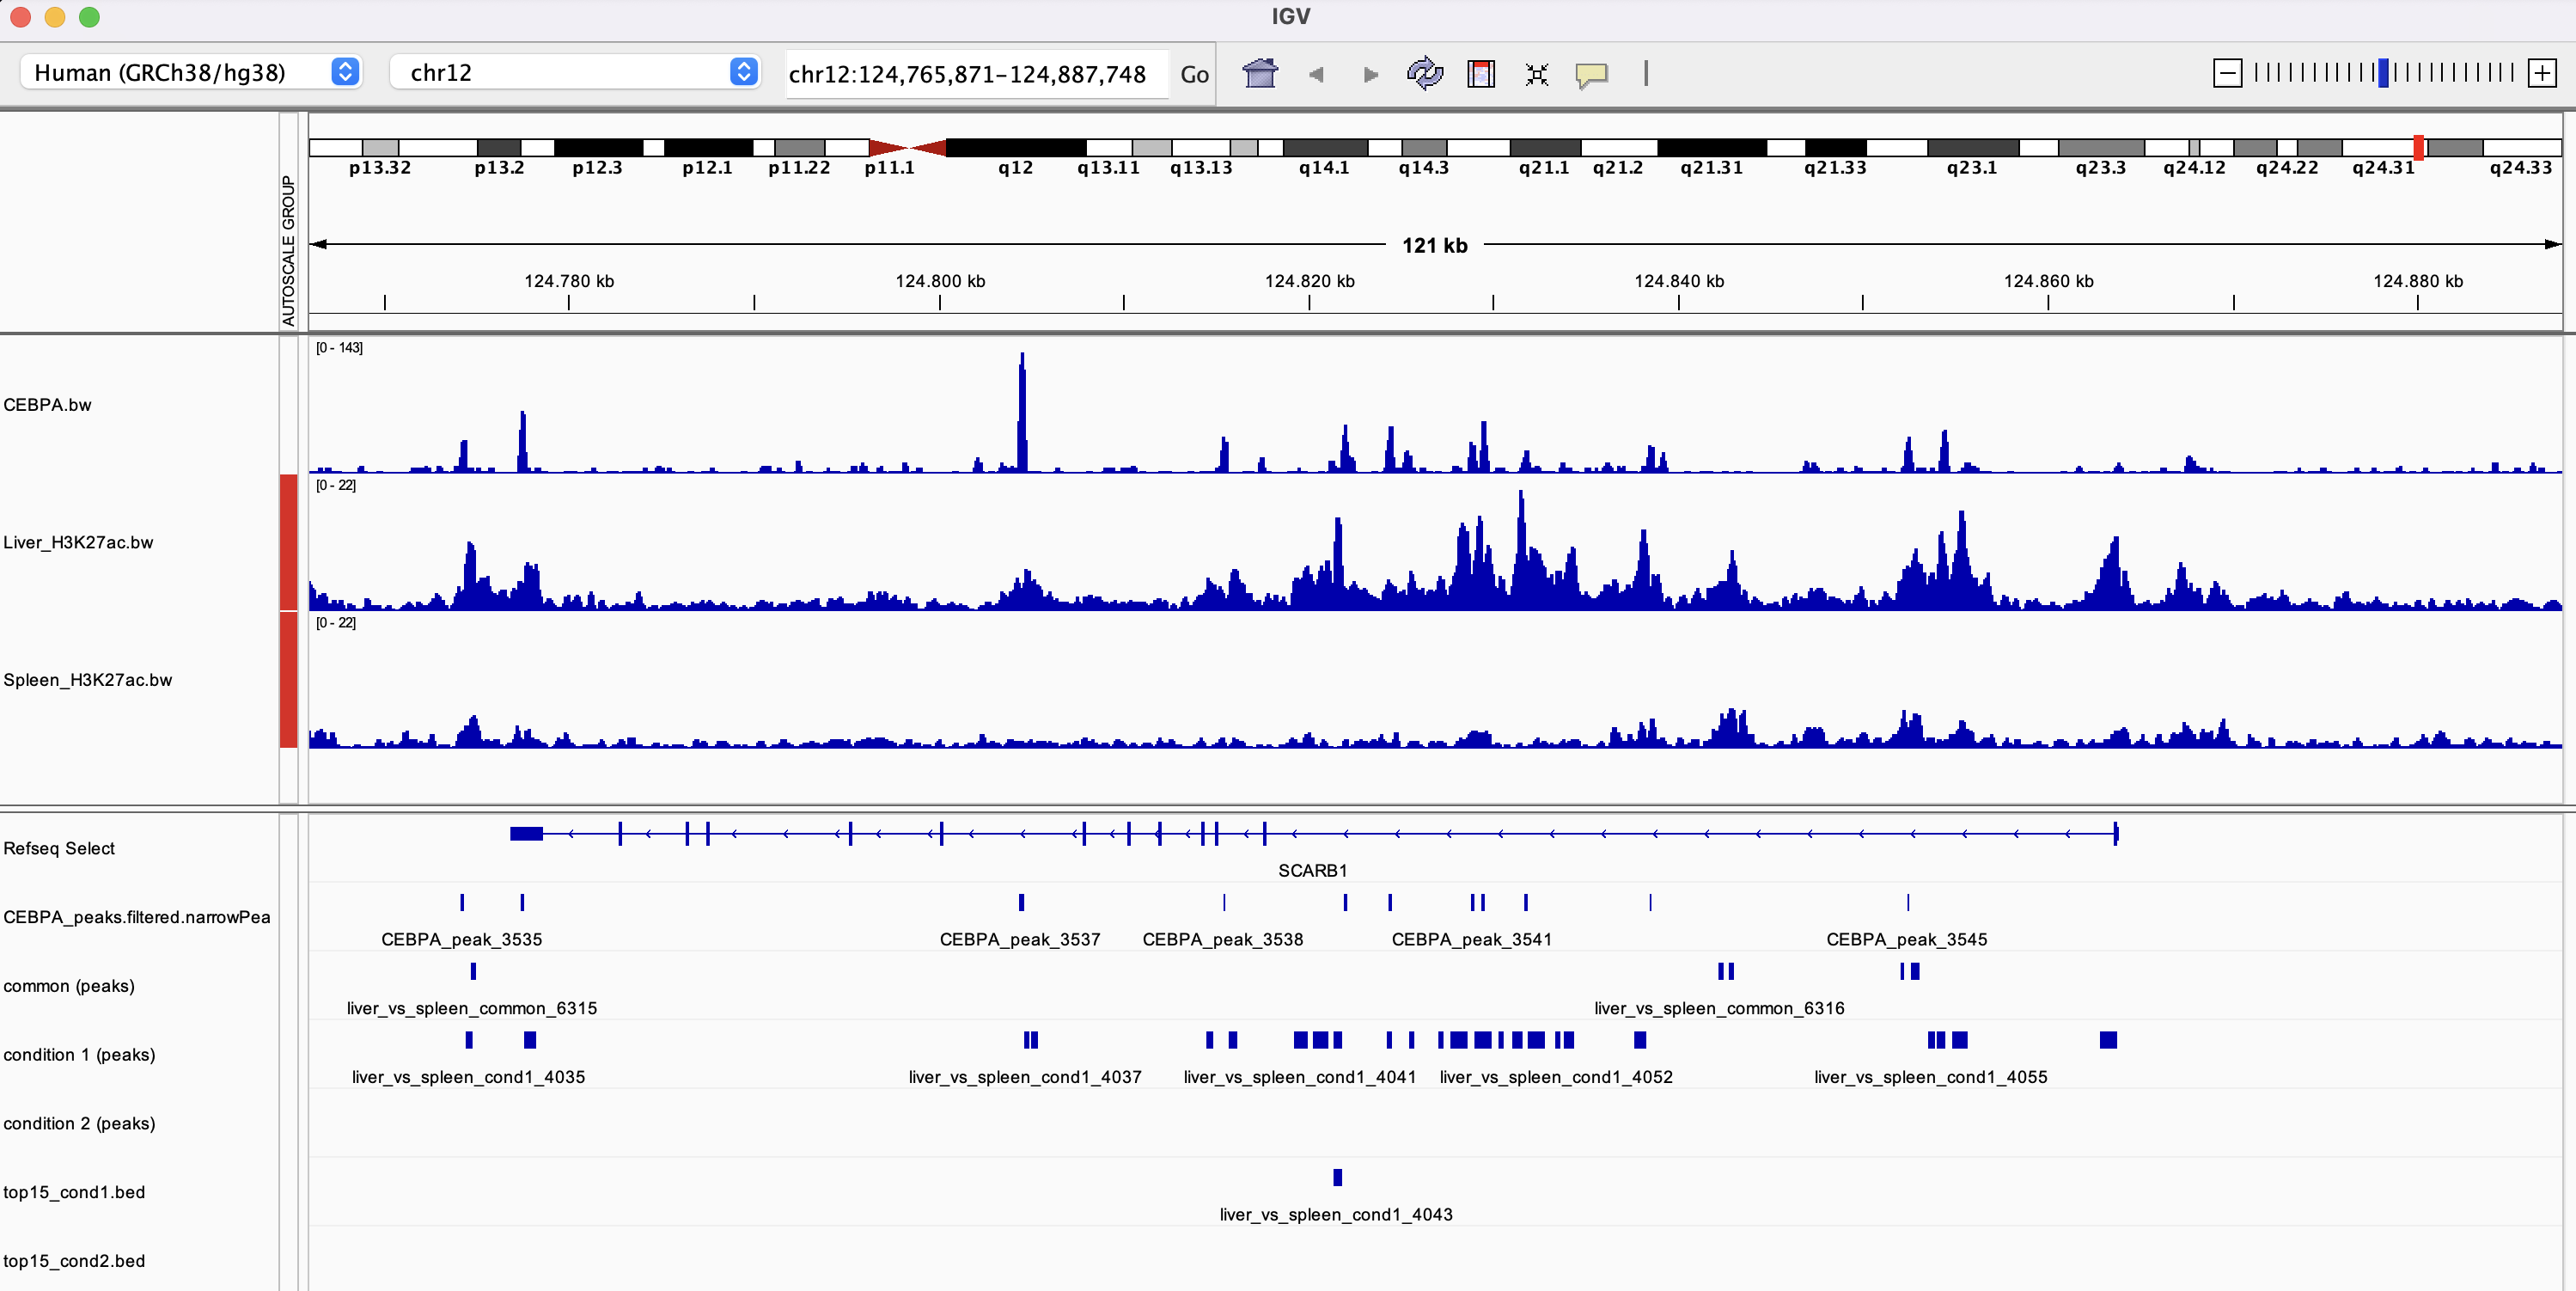
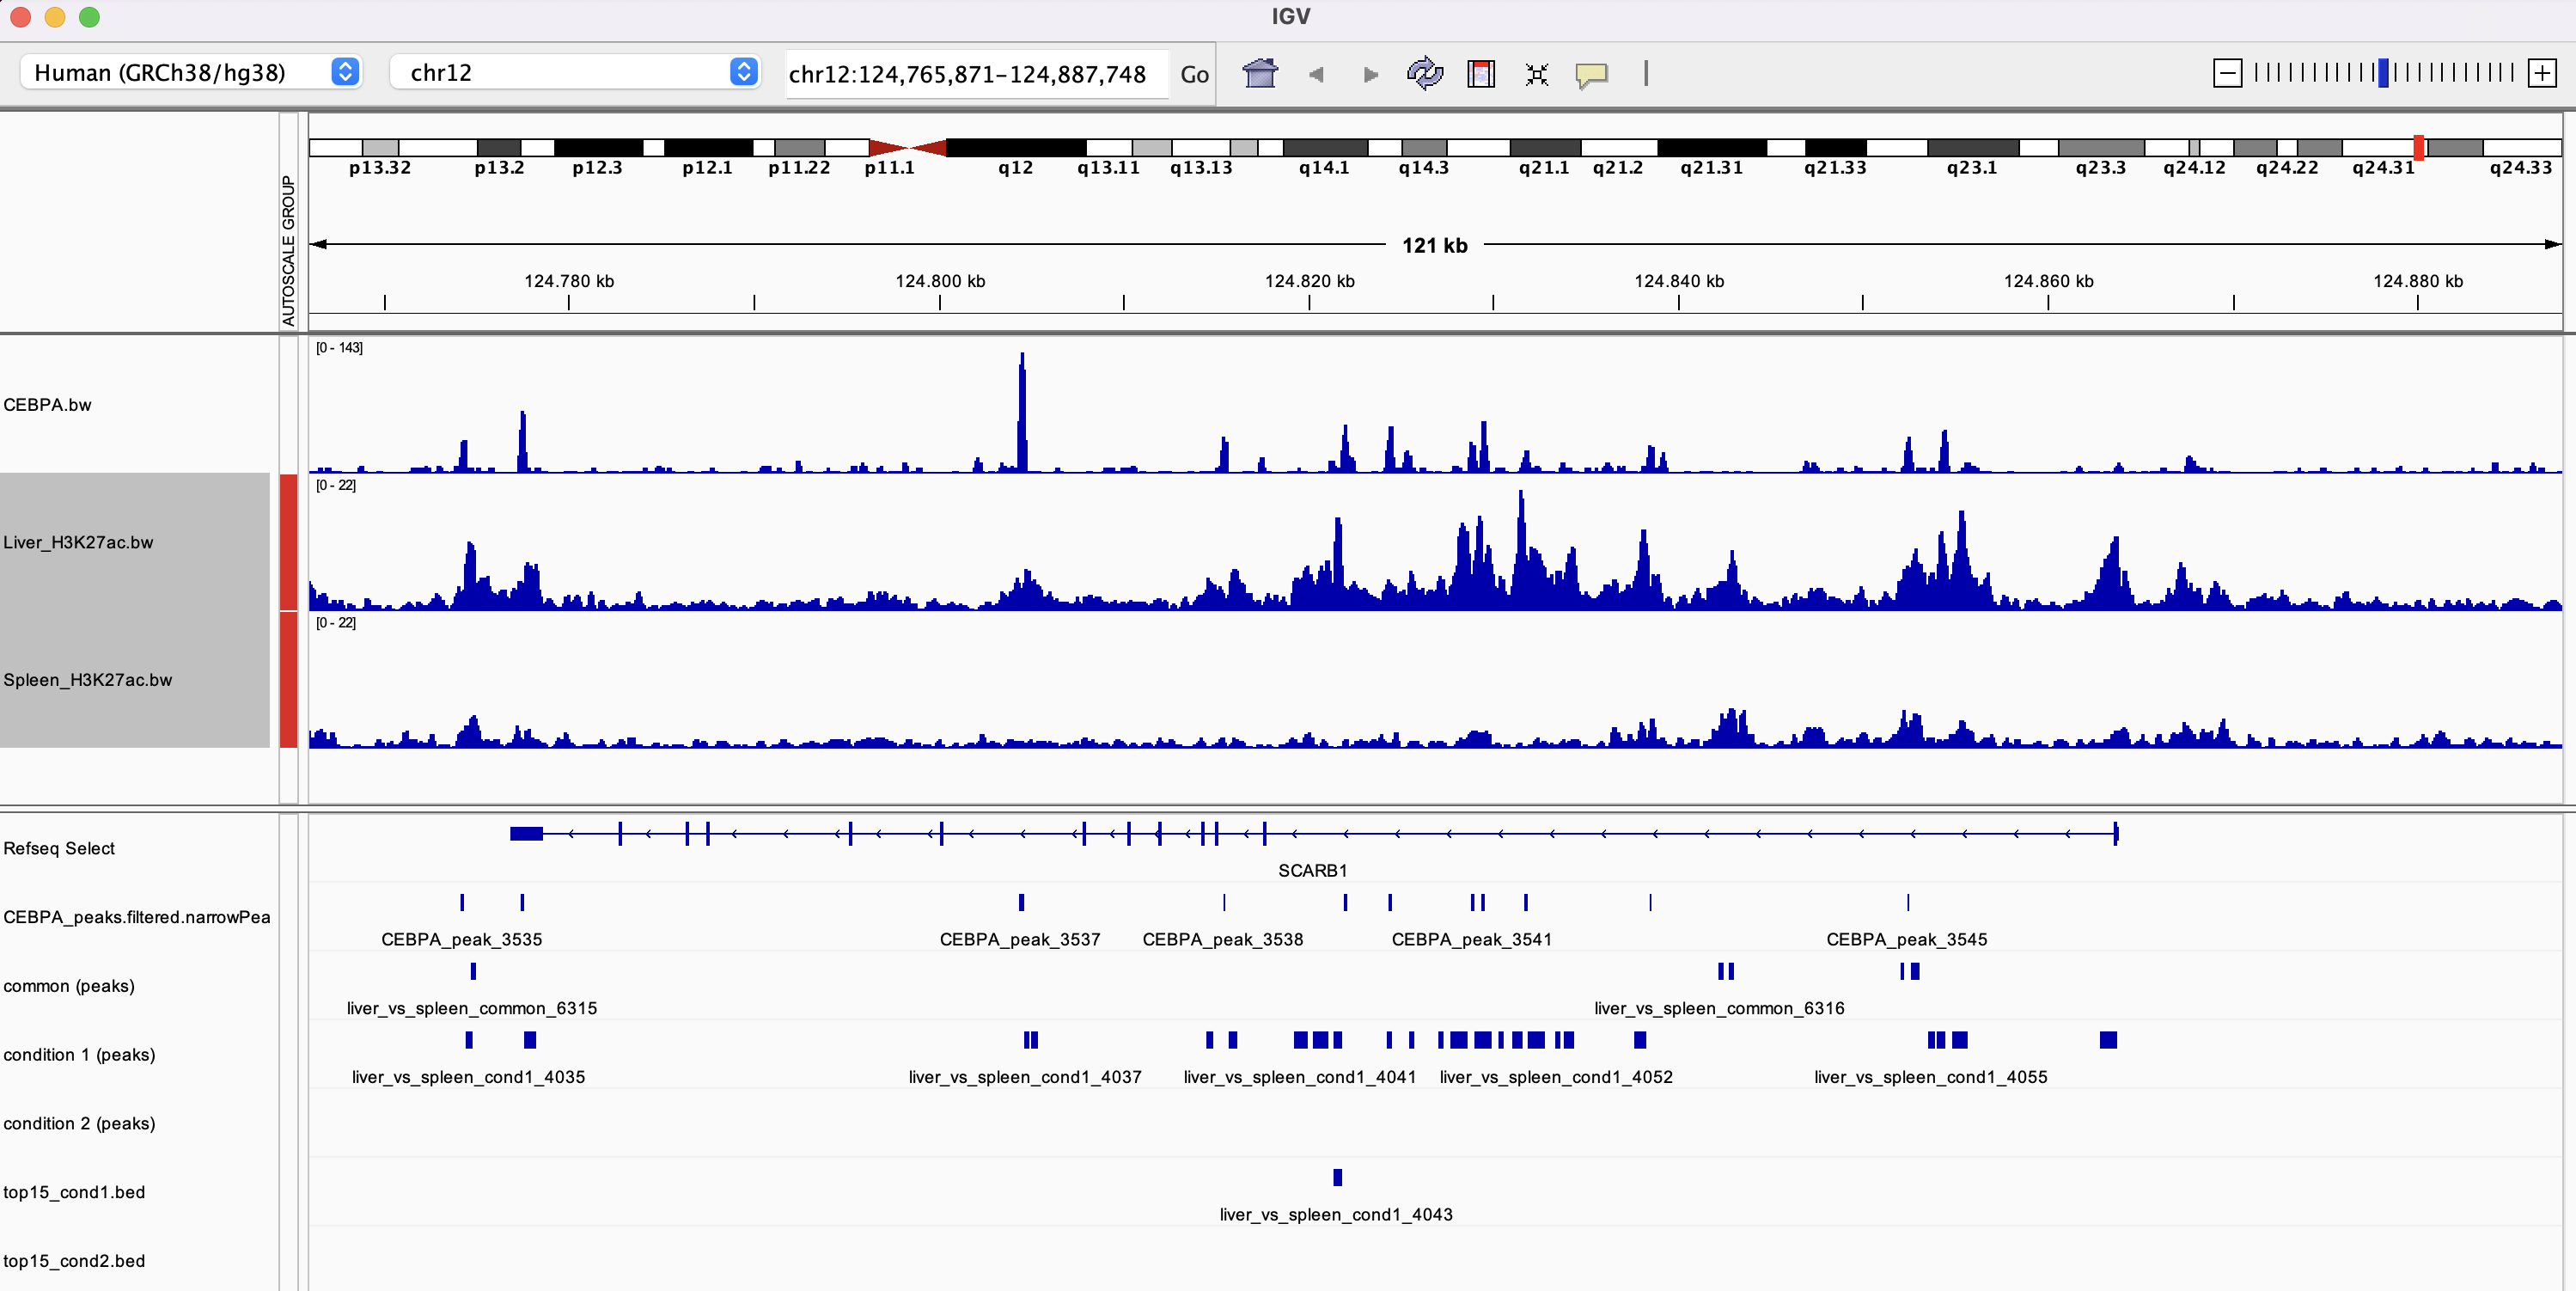

CSF3R

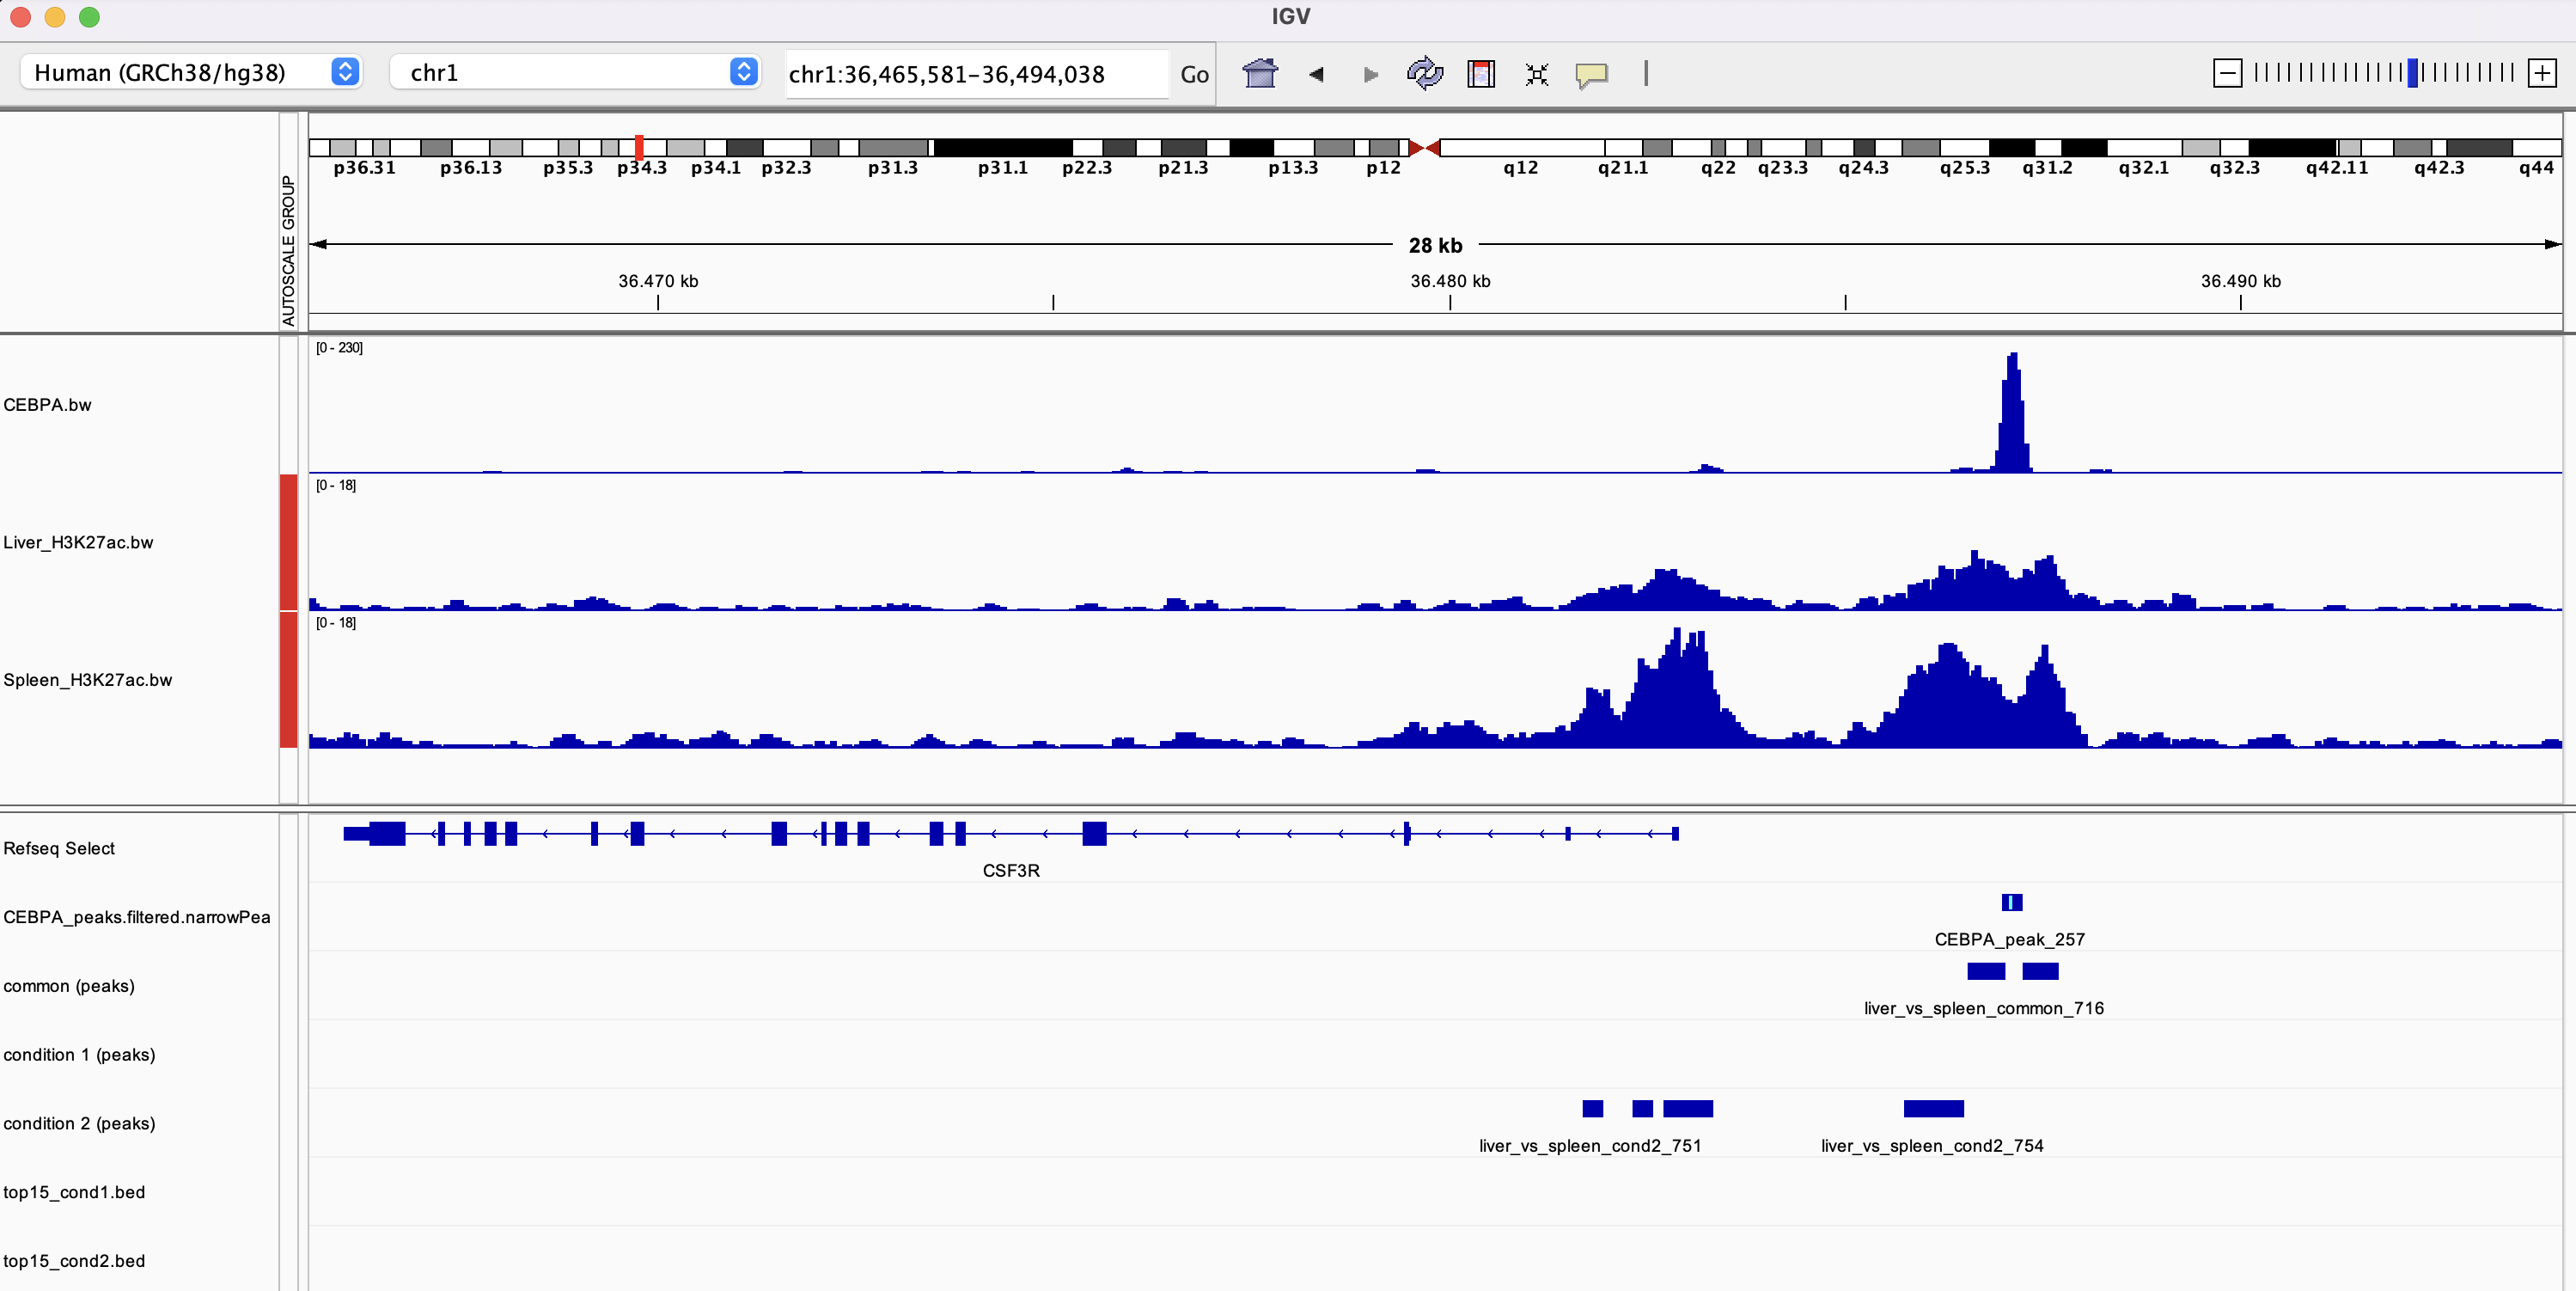

## Summary

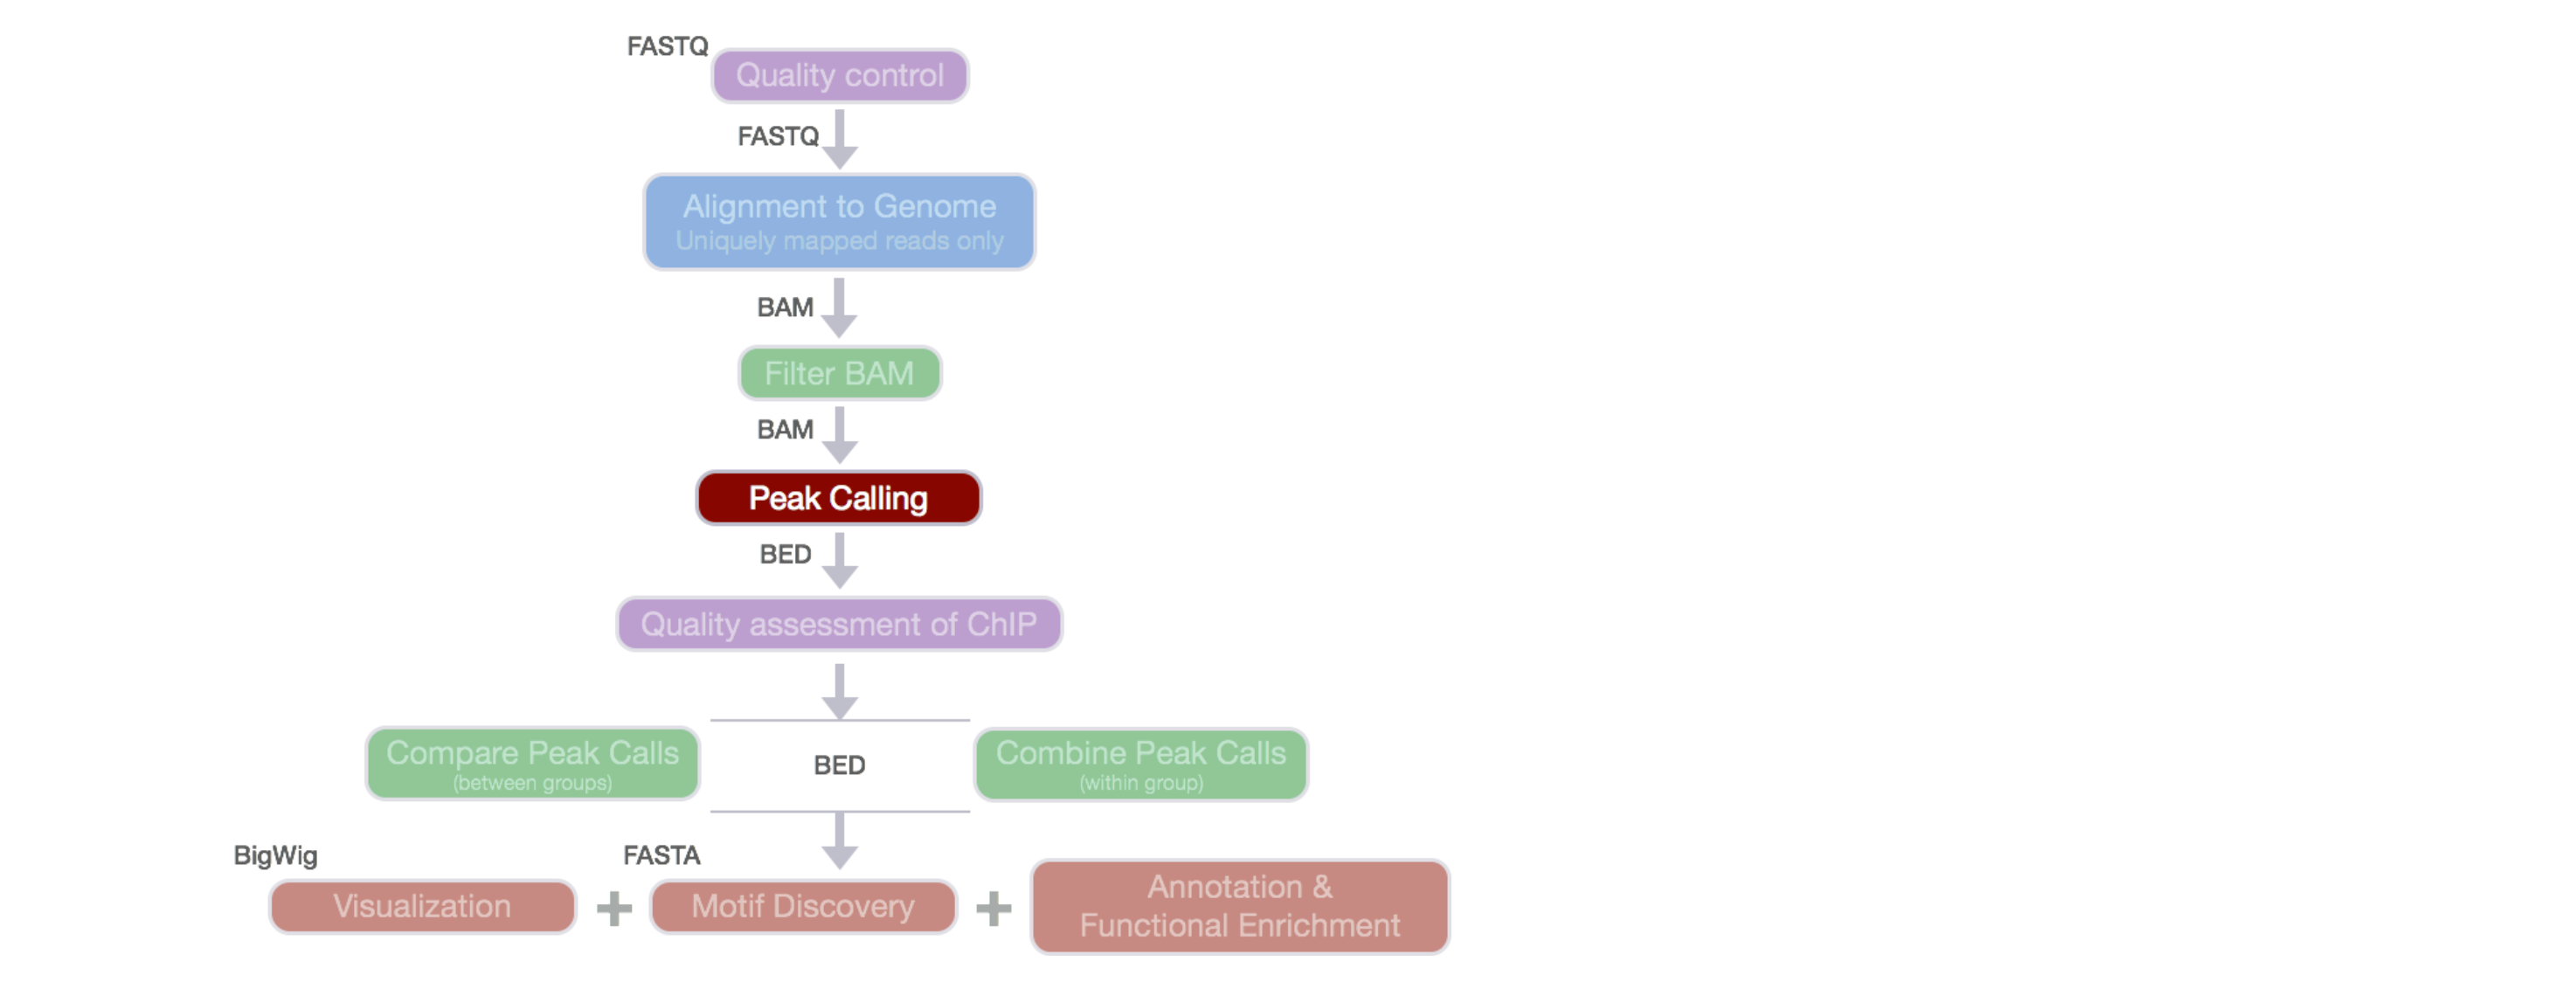

In this practical we:

1. downloaded the reads of a CEBPA ChIP-seq experiment and its Input from ENA, and checked their quality (FastQC, MultiQC)
2. aligned the reads to the human genome (bowtie2) and removed low quality alignments and duplicates (samtools)
3. visualised the alignments and coverage tracks in IGV (bigWig files made with deepTools) and checked the enrichment of the ChIP (fingerprint plot)
4. called peaks with MACS3, removed blacklisted regions and computed the FRiP
5. interpreted the peaks: location relative to genes, nearby genes, enriched motifs and gene ontology terms (HOMER)
6. compared the CEBPA peaks with the active enhancer mark H3K27ac in liver and spleen, and found regions with a different H3K27ac signal between both tissues (MACS3 bdgdiff)

Some steps that are often part of a ChIP-seq analysis but that we did not do here: comparing biological replicates (e.g. with [IDR](https://github.com/nboley/idr)), motif analysis with other tools (e.g. [MEME suite](https://meme-suite.org/), [pycisTarget](https://pycistarget.readthedocs.io/)) and integration with gene expression data (RNA-seq).